<a href="https://colab.research.google.com/github/ldelia22/16.32-Redes-Neuronales-en-Bioingenier-a-TP2/blob/main/TP2_MLP_DELIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 - Clasificación de texto con un MLP
### Redes Neuronales en Bioingeniería

Dataset: **20 Newsgroups** (20 categorías), con el mismo preprocesamiento, la misma vectorización TF-IDF y el mismo split train/validación que el TP1 (regresión softmax).

## Consigna
A partir de la notebook de Regresión Softmax, entrenar un **MLP** cuya búsqueda de hiperparámetros incluya al menos:

- distintas funciones de activación;
- distintas cantidades de capas ocultas (1, 2 o 3);
- distintas cantidades de neuronas por capa;
- distintos optimizadores con distintos parámetros: Adam, RMSProp, SGD, momentos de orden 1 y 2;
- los hiperparámetros buscados en el TP anterior (preprocesamiento, learning rate, batch size).

Además, encontrar una cantidad de capas y de unidades ocultas que deje el problema **sobreajustado**, analizar todos los entrenamientos y comparar performance y tiempos. **Bonus:** pruning en Optuna.

## Cómo está organizada la entrega

Dónde está cada punto de la consigna:

- Modelo MLP (capas ocultas, funciones de activación y dropout): sección 3.
- Optimizadores y momentos de orden 1 y 2 (SGD, RMSProp y Adam): sección 3.2.
- Verificación de que los entrenamientos son reproducibles: sección 3.3.
- Búsqueda de hiperparámetros con Optuna, con los pedidos en la consigna, los del TP1 y pruning: sección 4.
- Análisis de la búsqueda e importancia de cada hiperparámetro: sección 4.1.
- Pruning (bonus): sección 4.2, que compara la búsqueda con pruning contra la misma búsqueda sin pruning.
- Documentos que ningún modelo puede separar y accuracy máxima alcanzable en train: sección 5.0.
- Efecto controlado de la activación y del ancho: sección 5, experimentos A y C.
- Profundidad, con una búsqueda de hiperparámetros propia para cada cantidad de capas (0 a 3): sección 5, experimento B.
- Optimizadores y momentos, con una búsqueda propia para cada optimizador y variaciones de los momentos a paso efectivo constante: sección 5, experimento D.
- Configuración sobreajustada (barrido de capas × unidades) y cómo corregirla: sección 5, experimentos E y F.
- Comparación de performance y tiempos a lo ancho de todos los entrenamientos: sección 6.
- Modelo final en test: sección 7.
- Comparación con la regresión softmax (bonus): sección 5 B en validación (la softmax entra como 0 capas ocultas, con su propia búsqueda de hiperparámetros) y sección 7 en test (contra una softmax ajustada con el mismo preprocesamiento y contra la del TP1).
- Conclusiones: sección 8.

Resultados principales:

- **Modelo final:** un MLP de **una sola capa oculta de 1024 unidades** con ELU, dropout 0.08 y Adam ($\eta = 2.3\cdot10^{-4}$), sobre unigramas lematizados, sin stopwords y con 40.000 términos. Llega a **0.7733** de accuracy de validación, contra 0.7565 de una regresión softmax ajustada con el mismo preprocesamiento. (La búsqueda sin pruning tuvo un trial con 0.7751; la diferencia, 0.2 puntos, es mucho menor que el error estándar de ~0.9 puntos.)
- **Profundidad:** con una búsqueda de hiperparámetros propia para cada profundidad, el mejor resultado es 0.7565 sin capas ocultas, **0.7711 con una**, 0.7552 con dos y 0.7221 con tres. Agregar capas no mejora, y con tres empeora claramente.
- **Optimizadores:** ajustados cada uno por separado, Adam (0.7733) y RMSProp (0.7698) superan a SGD (0.7371). A paso efectivo constante, el momento de orden 1 es lo que le permite a SGD entrenar, sin momento, ese mismo paso diverge.
- **Sobreajuste:** la red **3 × 2048 sin regularización** (90 millones de parámetros) queda claramente sobreajustada. Llega al techo de train en pocas épocas, su loss de validación sube de 1.157 a 2.714 desde la época 2 y su mejor accuracy de validación es 0.698.
- **Pruning:** recorta un 56 % de las épocas y un 23 % del tiempo de la búsqueda, pero no mejoró el resultado: la búsqueda con pruning llegó a 0.7689 y la búsqueda sin pruning a 0.7751, una diferencia menor que el error estándar.
- **Test:** el MLP obtiene **0.7079** de accuracy (F1 macro 0.699). Supera por 2.0 puntos a la regresión softmax con el mismo preprocesamiento (0.6884) y por 3.3 a la del TP1 (0.6751). La red sobreajustada queda en 0.6232.

## 0. Setup

**Reproducibilidad.** Se fijan las semillas de Python, NumPy y PyTorch; el orden de los batches sale de un generador con semilla fija; se le pide a PyTorch que use algoritmos deterministas en cuDNN/cuBLAS (`torch.use_deterministic_algorithms`, que avisa si alguna operación no tiene versión determinista) y se desactiva TF32. Esto importa especialmente con Optuna: TPE elige cada trial según los resultados anteriores y el pruner compara contra la mediana, así que una diferencia mínima en un trial cambiaría el camino de toda la búsqueda. La sección 3.3 verifica que entrenar dos veces el mismo modelo da exactamente los mismos números.

In [ ]:
!pip install -q mlflow optuna

In [ ]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # antes de importar torch: cuBLAS determinista en GPU

import re, io, time, random, contextlib, warnings, platform
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

import sklearn
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import optuna

SEED = 42


def set_seed(seed):
    """Fija las semillas de Python, NumPy y PyTorch (CPU y GPU)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# MODO_RAPIDO = True achica datos, trials y épocas para verificar en pocos minutos que todo corre.
# La entrega se ejecuta con MODO_RAPIDO = False.
MODO_RAPIDO = os.environ.get("TP2_MODO_RAPIDO", "0") == "1"

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("mlp_20newsgroups")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

gpu = torch.cuda.get_device_name(0) if device.type == "cuda" else "-"
print(f"Python {platform.python_version()} | torch {torch.__version__} | scikit-learn {sklearn.__version__} | "
      f"optuna {optuna.__version__} | mlflow {mlflow.__version__}")
print(f"Dispositivo: {device} | GPU: {gpu} | hilos CPU: {torch.get_num_threads()} | MODO_RAPIDO = {MODO_RAPIDO}")
if device.type != "cuda":
    print("ATENCIÓN: no hay GPU; los barridos de la sección 5 van a tardar bastante más.")

Python 3.13.15 | torch 2.11.0+cu130 | scikit-learn 1.6.1 | optuna 5.0.0 | mlflow 3.17.1
Dispositivo: cuda | GPU: Tesla T4 | hilos CPU: 1 | MODO_RAPIDO = False


In [ ]:
for pkg in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

## 1. Datos y preprocesamiento (igual que en el TP1)

Se reutilizan sin cambios `preprocess_text` y `vectorize_data` del TP1, el caché de las 6 combinaciones de stopwords × normalización y el split estratificado 80/20 con `random_state=42`. Así los números de validación de este TP son comparables con los del TP1.

In [ ]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)

train_data, y_train_all = list(newsgroups_train.data), np.asarray(newsgroups_train.target)
test_data, y_test_all = list(newsgroups_test.data), np.asarray(newsgroups_test.target)
if MODO_RAPIDO:
    train_data, y_train_all = train_data[:2500], y_train_all[:2500]
    test_data, y_test_all = test_data[:1000], y_test_all[:1000]
print(f"Clases: {NUM_CLASSES} | Train: {len(train_data)} documentos | Test: {len(test_data)} documentos")

Clases: 20 | Train: 11314 documentos | Test: 7532 documentos


In [ ]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)


def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)    # vocabulario e IDF aprendidos solo con train
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


print("Precalculando el preprocesamiento de las 6 combinaciones (tarda unos minutos)...")
preprocessed_cache, preprocessing_times = {}, {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        t0 = time.perf_counter()
        preprocessed_cache[(remove_stopwords, normalization)] = (
            [preprocess_text(t, remove_stopwords, normalization) for t in train_data],
            [preprocess_text(t, remove_stopwords, normalization) for t in test_data])
        preprocessing_times[(remove_stopwords, normalization)] = time.perf_counter() - t0
        print(f"  listo: {(remove_stopwords, normalization)}  ({preprocessing_times[(remove_stopwords, normalization)]:.1f} s)")

Precalculando el preprocesamiento de las 6 combinaciones (tarda unos minutos)...
  listo: (False, 'none')  (34.8 s)
  listo: (False, 'stem')  (48.6 s)
  listo: (False, 'lemmatize')  (32.4 s)
  listo: (True, 'none')  (21.0 s)
  listo: (True, 'stem')  (40.4 s)
  listo: (True, 'lemmatize')  (25.5 s)


In [ ]:
# Split train/validación fijo (el mismo del TP1). El test oficial no se usa hasta la sección 7.
idx_tr, idx_val = train_test_split(np.arange(len(train_data)), test_size=0.2, random_state=SEED, stratify=y_train_all)
y_tr_s, y_val_s = y_train_all[idx_tr], y_train_all[idx_val]
y_tr_t = torch.tensor(y_tr_s, dtype=torch.long, device=device)
y_val_t = torch.tensor(y_val_s, dtype=torch.long, device=device)
NGRAMS = {"1gram": (1, 1), "1_2gram": (1, 2)}


def split_texts(texts):
    return [texts[i] for i in idx_tr], [texts[i] for i in idx_val]


def to_device_dense(X):
    """Matriz dispersa de scipy -> tensor denso float32 en `device`, sin armar la matriz densa en la CPU."""
    X = X.tocsr().astype(np.float32)
    t = torch.sparse_csr_tensor(torch.from_numpy(X.indptr).long(), torch.from_numpy(X.indices).long(),
                                torch.from_numpy(X.data), size=X.shape)
    return t.to(device).to_dense()


PREPRO_KEYS = ["remove_stopwords", "normalization", "ngram_range", "max_features", "min_df"]
_sparse_cache = {}                      # configuración de preprocesamiento -> (X_tr, X_val) dispersas
_dense_last = {"key": None, "data": None}


def get_split_data(cfg):
    """Devuelve X_tr y X_val densos en device, más los tiempos de vectorizar y de pasar a tensor.
    Las matrices dispersas se cachean (ocupan poco); la versión densa se reutiliza si el trial anterior usó la misma."""
    key = tuple(cfg[k] for k in PREPRO_KEYS)
    t0 = time.perf_counter()
    if key not in _sparse_cache:
        tr, val = split_texts(preprocessed_cache[(cfg["remove_stopwords"], cfg["normalization"])][0])
        X_tr, X_val, _ = vectorize_data(tr, val, NGRAMS[cfg["ngram_range"]], cfg["max_features"], cfg["min_df"])
        _sparse_cache[key] = (X_tr, X_val)
    t1 = time.perf_counter()
    if _dense_last["key"] != key:
        _dense_last["data"] = None
        if device.type == "cuda":
            torch.cuda.empty_cache()
        _dense_last["data"] = tuple(to_device_dense(X) for X in _sparse_cache[key])
        _dense_last["key"] = key
    t2 = time.perf_counter()
    return (*_dense_last["data"], t1 - t0, t2 - t1)


print(f"Train de búsqueda: {len(idx_tr)} docs | Validación: {len(idx_val)} docs")

Train de búsqueda: 9051 docs | Validación: 2263 docs


## 2. Del modelo lineal al MLP

La regresión softmax del TP1 calcula los logits directamente como $z = Wx + b$: cada palabra suma siempre lo mismo al logit de cada clase y las fronteras de decisión son hiperplanos. Un **perceptrón multicapa (MLP)** intercala $L$ capas ocultas, cada una con una transformación lineal seguida de una función de activación no lineal $f$:

$$
h^{(0)} = x,\qquad h^{(l)} = f\big(W^{(l)} h^{(l-1)} + b^{(l)}\big)\ \ (l = 1,\dots,L),\qquad z = W^{(L+1)} h^{(L)} + b^{(L+1)}.
$$

Sin $f$, las capas se podrían multiplicar entre sí y el modelo volvería a ser lineal. Con $f$, cada unidad oculta puede activarse ante **combinaciones** de palabras (por ejemplo, "window" junto a "server" y no junto a "driver"), y la red aprende una representación intermedia $h$ en lugar de usar TF-IDF tal cual. La salida y la función de costo no cambian: logits sin softmax y `CrossEntropyLoss`.

El costo es la cantidad de parámetros. Con $d$ entradas, capas de $n_1,\dots,n_L$ unidades y $K=20$ clases:

$$
P = \sum_{l=1}^{L+1} (n_{l-1}+1)\,n_l,\qquad n_0=d,\ n_{L+1}=K.
$$

Con $d = 10\,000$, una sola capa de 512 unidades ya tiene $10\,001\cdot512 + 513\cdot20 \approx 5{,}1$ millones de parámetros, 25 veces más que los 200.020 de la regresión softmax, para 9.051 documentos de entrenamiento. Casi toda la capacidad está en la primera capa ($d\cdot n_1$), por eso el tamaño del vocabulario y el ancho de la primera capa dominan el costo y el riesgo de sobreajuste. Además la función de costo deja de ser convexa: el resultado depende de la inicialización, del optimizador y de sus hiperparámetros.

## 3. Modelo

### 3.1 MLP configurable

`MLP` recibe la lista de tamaños de las capas ocultas (vacía = regresión softmax del TP1), el nombre de la activación y la probabilidad de dropout. Las activaciones que se comparan:

| Activación | $f(z)$ | $f'(z)$ | Comentario |
|---|---|---|---|
| ReLU | $\max(0,z)$ | 0 o 1 | No satura para $z>0$; unidades con $z<0$ siempre quedan "muertas" (gradiente 0). |
| Leaky ReLU | $\max(0.01z, z)$ | 0.01 o 1 | Como ReLU pero deja pasar un gradiente chico para $z<0$. |
| ELU | $z$ si $z>0$, $e^z-1$ si no | suave | Salidas negativas acotadas, media de activaciones más cerca de 0. |
| GELU | $z\,\Phi(z)$ | suave | Versión suave de ReLU (la de los Transformers). |
| tanh | $\tanh z$ | $\le 1$ | Centrada en 0, satura para $|z|$ grande. |
| sigmoide | $1/(1+e^{-z})$ | $\le 0.25$ | Satura y no está centrada: en cada capa el gradiente se multiplica por $\le 0.25$, y con varias capas se desvanece. |

El **dropout** apaga al azar una fracción $p$ de las unidades ocultas en cada paso de entrenamiento (y escala las restantes por $1/(1-p)$); en evaluación no se aplica. Obliga a que la red no dependa de unidades particulares y actúa como regularizador.

In [ ]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": lambda: nn.LeakyReLU(0.01),
    "elu": nn.ELU,
    "gelu": nn.GELU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, num_classes, activation="relu", dropout=0.0):
        super().__init__()
        layers, d = [], input_dim
        for h in hidden_sizes:
            layers += [nn.Linear(d, h), ACTIVATIONS[activation]()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, num_classes))     # capa de salida: logits, sin softmax
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


# Sanity checks
_m = MLP(10000, [512, 128], NUM_CLASSES, "relu", 0.3)
print(_m)
print("Parámetros:", count_params(_m), "| fórmula:", (10000 + 1) * 512 + (512 + 1) * 128 + (128 + 1) * NUM_CLASSES)
print("Sin capas ocultas = regresión softmax del TP1:", count_params(MLP(10000, [], NUM_CLASSES)), "parámetros")
set_seed(SEED)
_x = torch.rand(256, 10000) * (torch.rand(256, 10000) < 0.01)
_x = _x / _x.norm(dim=1, keepdim=True)
for act in ACTIVATIONS:
    set_seed(SEED)
    loss0 = F.cross_entropy(MLP(10000, [256, 256], NUM_CLASSES, act)(_x), torch.randint(0, NUM_CLASSES, (256,))).item()
    print(f"loss inicial con {act:10s}: {loss0:.4f}  (ln 20 = {np.log(NUM_CLASSES):.4f})")

MLP(
  (net): Sequential(
    (0): Linear(in_features=10000, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=20, bias=True)
  )
)
Parámetros: 5188756 | fórmula: 5188756
Sin capas ocultas = regresión softmax del TP1: 200020 parámetros
loss inicial con relu      : 2.9947  (ln 20 = 2.9957)
loss inicial con leaky_relu: 2.9947  (ln 20 = 2.9957)
loss inicial con elu       : 2.9959  (ln 20 = 2.9957)
loss inicial con gelu      : 2.9952  (ln 20 = 2.9957)
loss inicial con tanh      : 2.9959  (ln 20 = 2.9957)
loss inicial con sigmoid   : 3.0200  (ln 20 = 2.9957)


La loss inicial queda en $\approx\ln 20$ con todas las activaciones: con la inicialización por defecto de PyTorch (uniforme con escala $\frac{1}{\sqrt{\text{fan}_{\text{in}}}}$) los logits arrancan chicos y la red predice casi uniforme, igual que la regresión softmax. Es el control de que la red y las etiquetas están bien conectadas.

### 3.2 Optimizadores y momentos de orden 1 y 2

Con $g_t$ el gradiente del batch en el paso $t$ y $\eta$ el learning rate:

- **SGD**: $\theta_{t+1} = \theta_t - \eta\, g_t$.
- **SGD con momento (momento de orden 1)**: acumula un promedio de los gradientes pasados, $v_t = \mu v_{t-1} + g_t$, $\theta_{t+1} = \theta_t - \eta v_t$. Si el gradiente apunta siempre en la misma dirección, el paso efectivo tiende a $\eta/(1-\mu)$; si oscila, las oscilaciones se cancelan. **Nesterov** evalúa el momento "mirando adelante": $\theta_{t+1} = \theta_t - \eta\,(g_t + \mu v_t)$.
- **RMSProp (momento de orden 2)**: lleva un promedio exponencial del gradiente al cuadrado, $s_t = \alpha s_{t-1} + (1-\alpha) g_t^2$, y divide cada paso por su raíz: $\theta_{t+1} = \theta_t - \eta\, g_t/(\sqrt{s_t}+\epsilon)$. Cada peso tiene su propio paso efectivo: los que reciben gradientes chicos (palabras raras) avanzan tanto como los que reciben gradientes grandes. Admite además un momento de orden 1 sobre el paso normalizado (`momentum`).
- **Adam (momentos de orden 1 y 2)**: combina los dos, $m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t$ y $v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$, los corrige por sesgo ($\hat m_t = m_t/(1-\beta_1^t)$, $\hat v_t = v_t/(1-\beta_2^t)$) y actualiza $\theta_{t+1} = \theta_t - \eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$. Con $\beta_1 = 0$ es RMSProp con corrección de sesgo; $\beta_2$ fija cuánta historia entra en la escala del paso.

En la búsqueda cada optimizador tiene su propio rango de learning rate: con SGD el paso es $\eta g$ y los gradientes con entradas TF-IDF son chicos, así que necesita $\eta$ mucho mayores que RMSProp y Adam, cuyo paso es del orden de $\eta$ (TP1, sección 6.2 C). Todos usan `weight_decay` (penalización L2) como en el TP1.

In [ ]:
def make_optimizer(params, cfg):
    name, lr, wd = cfg["optimizer"], cfg["lr"], cfg.get("weight_decay", 0.0)
    if name == "sgd":
        mom = cfg.get("momentum", 0.0)
        return optim.SGD(params, lr=lr, momentum=mom, nesterov=bool(cfg.get("nesterov", False)) and mom > 0, weight_decay=wd)
    if name == "rmsprop":
        return optim.RMSprop(params, lr=lr, alpha=cfg.get("alpha", 0.99), momentum=cfg.get("momentum", 0.0), weight_decay=wd)
    if name == "adam":
        return optim.Adam(params, lr=lr, betas=(cfg.get("beta1", 0.9), cfg.get("beta2", 0.999)), weight_decay=wd)
    raise ValueError(name)

### 3.3 Loop de entrenamiento

`train_mlp` extiende el loop del TP1:

- Los datos se procesan en batches a partir de una permutación aleatoria de las muestras, generada con una semilla fija. De esta manera, se mantiene el mismo orden de procesamiento entre las distintas corridas, lo que facilita la comparación de los resultados.
- Al final de cada época mide loss y accuracy de validación (y, en los experimentos de la sección 5, también de train con el modelo en modo `eval`, es decir, sin dropout).
- Mide el tiempo de entrenamiento de cada época sincronizando las operaciones de la GPU, ya que estas se ejecutan de forma asíncrona y, sin sincronización, se mediría solo el tiempo de encolarlas.
- **Early stopping** opcional: corta si la accuracy de validación no mejora en `patience` épocas.
- **Pruning** opcional: si recibe un `trial` de Optuna, después de cada época le informa la mejor accuracy de validación alcanzada hasta ese momento y evalúa si conviene continuar con el entrenamiento (sección 4).
- Si la loss se vuelve `NaN`/`inf` (por ejemplo, debido a un learning rate demasiado grande), corta y marca la corrida como divergente.

In [ ]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def evaluate(model, X, y, chunk=4096):
    """Loss y accuracy sobre un conjunto completo, con el modelo en modo eval (sin dropout)."""
    model.eval()
    tot_loss, correct = 0.0, 0
    for i in range(0, len(X), chunk):
        logits = model(X[i:i + chunk])
        tot_loss += F.cross_entropy(logits, y[i:i + chunk], reduction="sum").item()
        correct += (logits.argmax(1) == y[i:i + chunk]).sum().item()
    return tot_loss / len(X), correct / len(X)


def train_mlp(cfg, X_tr, y_tr, X_val, y_val, *, epochs, patience=None, trial=None, eval_train=True,
              seed=SEED, writer=None):
    set_seed(seed)
    model = MLP(X_tr.shape[1], cfg["hidden"], NUM_CLASSES, cfg["activation"], cfg["dropout"]).to(device)
    opt = make_optimizer(model.parameters(), cfg)
    gen = torch.Generator().manual_seed(seed)
    n, bs = len(X_tr), cfg["batch_size"]
    h = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "epoch_time"]}
    best_acc, best_ep, status = -1.0, 0, "completed"

    for ep in range(1, epochs + 1):
        model.train()
        sync()
        t0 = time.perf_counter()
        perm = torch.randperm(n, generator=gen).to(device)
        run_loss = torch.zeros((), device=device)
        run_correct = torch.zeros((), device=device, dtype=torch.long)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            xb, yb = X_tr[idx], y_tr[idx]
            opt.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            opt.step()
            run_loss += loss.detach() * len(idx)
            run_correct += (logits.argmax(1) == yb).sum()
        sync()
        h["epoch_time"].append(time.perf_counter() - t0)

        if eval_train:
            tr_loss, tr_acc = evaluate(model, X_tr, y_tr)
        else:   # métricas acumuladas durante la época (más baratas; con dropout activo)
            tr_loss, tr_acc = run_loss.item() / n, run_correct.item() / n
        vl, va = evaluate(model, X_val, y_val)
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc"], [tr_loss, tr_acc, vl, va]):
            h[k].append(v)
        if writer is not None:
            writer.add_scalars("loss", {"train": tr_loss, "val": vl}, ep)
            writer.add_scalars("accuracy", {"train": tr_acc, "val": va}, ep)

        if not (np.isfinite(tr_loss) and np.isfinite(vl)):
            status = "diverged"
            break
        if va > best_acc:
            best_acc, best_ep = va, ep
        if trial is not None:
            trial.report(best_acc, ep)
            if trial.should_prune():
                status = "pruned"
                break
        if patience is not None and ep - best_ep >= patience:
            status = "early_stop"
            break

    h.update(best_val_acc=max(best_acc, 0.0), best_epoch=best_ep, status=status, epochs_run=len(h["val_acc"]),
             n_params=count_params(model), train_time=float(np.sum(h["epoch_time"])))
    return model, h

### Verificación de reproducibilidad

Se entrena dos veces el mismo modelo (una capa de 256 unidades con dropout, para que también intervenga el generador aleatorio del dropout) y se comparan las métricas época por época. Además se capturan los avisos de PyTorch sobre operaciones sin versión determinista.

In [ ]:
_cfg = {"remove_stopwords": True, "normalization": "stem", "ngram_range": "1gram", "max_features": 10000, "min_df": 2,
        "batch_size": 64, "hidden": [256], "activation": "relu", "dropout": 0.3, "weight_decay": 0.0,
        "optimizer": "adam", "lr": 1e-3}
_X_tr, _X_val, _, _ = get_split_data(_cfg)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    _, _h1 = train_mlp(_cfg, _X_tr, y_tr_t, _X_val, y_val_t, epochs=3)
    _, _h2 = train_mlp(_cfg, _X_tr, y_tr_t, _X_val, y_val_t, epochs=3)
for k in ["train_loss", "val_loss", "val_acc"]:
    print(f"{k:10s} corrida 1: {np.round(_h1[k], 6)} | corrida 2: {np.round(_h2[k], 6)} | idénticas: {_h1[k] == _h2[k]}")
avisos = sorted({str(w.message)[:150] for w in caught if "determinis" in str(w.message).lower()})
print("Avisos de operaciones sin versión determinista:", avisos if avisos else "ninguno")

train_loss corrida 1: [1.781129 0.862645 0.535883] | corrida 2: [1.781129 0.862645 0.535883] | idénticas: True
val_loss   corrida 1: [1.895804 1.154403 0.962095] | corrida 2: [1.895804 1.154403 0.962095] | idénticas: True
val_acc    corrida 1: [0.650464 0.722492 0.743261] | corrida 2: [0.650464 0.722492 0.743261] | idénticas: True
Avisos de operaciones sin versión determinista: ninguno


## 4. Búsqueda de hiperparámetros con Optuna y pruning

### Espacio de búsqueda

| Grupo | Hiperparámetro | Valores |
|---|---|---|
| Preprocesamiento (TP1) | `remove_stopwords` | False, True |
| | `normalization` | none, stem, lemmatize |
| | `ngram_range` | 1gram, 1_2gram |
| | `max_features` | 5000, 10000, 20000, 40000 |
| | `min_df` | 1, 2, 5 |
| Entrenamiento (TP1) | `batch_size` | 32, 64, 128, 256 |
| Arquitectura | `n_layers` | 1, 2, 3 |
| | `n_units_l0`, `n_units_l1`, `n_units_l2` | 64, 128, 256, 512, 1024 (cada capa por separado) |
| | `activation` | relu, leaky_relu, elu, gelu, tanh, sigmoid |
| Regularización | `dropout` | 0 a 0.6 |
| | `use_weight_decay`, `weight_decay` | False/True; si True, $10^{-7}$ a $10^{-3}$ (log) |
| Optimizador | `optimizer` | sgd, rmsprop, adam |
| SGD | `lr_sgd`, `sgd_momentum`, `sgd_nesterov` | $10^{-2}$ a 3 (log), 0 a 0.99, False/True |
| RMSProp | `lr_rmsprop`, `rmsprop_alpha`, `rmsprop_momentum` | $10^{-4}$ a $10^{-2}$ (log), 0.8 a 0.999, 0 a 0.95 |
| Adam | `lr_adam`, `adam_beta1`, `adam_beta2` | $10^{-4}$ a $10^{-2}$ (log), 0.5 a 0.99, 0.9 a 0.9999 |

Respecto del TP1 se amplió `max_features` hasta 40.000, porque ahí el mejor valor quedó en el borde del rango (10.000). El weight decay incluye la opción de no usarlo (`use_weight_decay=False`): así "sin regularización L2" es un valor más del espacio y no queda representado por el borde inferior de un rango logarítmico. Los hiperparámetros de cada optimizador son **condicionales**: solo existen en los trials que usan ese optimizador, igual que `n_units_l1` y `n_units_l2` solo existen con 2 o 3 capas. Por eso el learning rate tiene un nombre por optimizador y el sampler se configura con `multivariate=True, group=True`, que modela juntos los parámetros que aparecen juntos.

### Objetivo, early stopping y pruning

Cada trial entrena hasta `MAX_EPOCHS_SEARCH` épocas y devuelve la **mejor accuracy de validación** alcanzada (en el TP1 se usaba la de la última época; un MLP sobreajusta en pocas épocas y la última sería una medida pesimista e inestable). Hay dos mecanismos que cortan entrenamientos antes de tiempo:

- **Early stopping** (dentro del trial): si la accuracy de validación no mejora en `PATIENCE` épocas, seguir entrenando no puede cambiar el objetivo.
- **Pruning** (entre trials): después de cada época el trial reporta su mejor accuracy hasta el momento. `MedianPruner` lo **poda** si ese valor es peor que la mediana de lo que habían logrado los trials anteriores en la misma época. Un trial con un learning rate malo o una activación que no aprende se descarta a las 3 o 4 épocas en vez de completar todas. El pruner no actúa en los primeros `n_startup_trials` trials (necesita referencias) ni antes de `n_warmup_steps` épocas (las primeras épocas son ruidosas y algunas configuraciones arrancan lento).

El pruning reduce el tiempo de búsqueda, pero puede descartar configuraciones que empiezan aprendiendo más lento y después obtienen buenos resultados. Por eso, se usa la mejor accuracy alcanzada hasta cada época, en lugar de la de esa época en particular, para evitar descartar un modelo por una caída puntual.

In [ ]:
N_TRIALS = 8 if MODO_RAPIDO else 120
MAX_EPOCHS_SEARCH = 4 if MODO_RAPIDO else 20
PATIENCE = 4
UNITS = [64, 128, 256, 512, 1024]
OPT_KEYS = ["lr_sgd", "sgd_momentum", "sgd_nesterov", "lr_rmsprop", "rmsprop_alpha", "rmsprop_momentum",
            "lr_adam", "adam_beta1", "adam_beta2"]


def suggest_optimizer_params(trial, opt):
    if opt == "sgd":
        trial.suggest_float("lr_sgd", 1e-2, 3.0, log=True)
        trial.suggest_float("sgd_momentum", 0.0, 0.99)
        trial.suggest_categorical("sgd_nesterov", [False, True])
    elif opt == "rmsprop":
        trial.suggest_float("lr_rmsprop", 1e-4, 1e-2, log=True)
        trial.suggest_float("rmsprop_alpha", 0.8, 0.999)
        trial.suggest_float("rmsprop_momentum", 0.0, 0.95)
    else:
        trial.suggest_float("lr_adam", 1e-4, 1e-2, log=True)
        trial.suggest_float("adam_beta1", 0.5, 0.99)
        trial.suggest_float("adam_beta2", 0.9, 0.9999)


def suggest_regularization(trial, dropout=True):
    if dropout:
        trial.suggest_float("dropout", 0.0, 0.6)
    if trial.suggest_categorical("use_weight_decay", [False, True]):
        trial.suggest_float("weight_decay", 1e-7, 1e-3, log=True)


def suggest_params(trial):
    trial.suggest_categorical("remove_stopwords", [False, True])
    trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    trial.suggest_categorical("max_features", [5000, 10000, 20000, 40000])
    trial.suggest_categorical("min_df", [1, 2, 5])
    trial.suggest_categorical("batch_size", [32, 64, 128, 256])
    n_layers = trial.suggest_int("n_layers", 1, 3)
    for i in range(n_layers):
        trial.suggest_categorical(f"n_units_l{i}", UNITS)
    trial.suggest_categorical("activation", list(ACTIVATIONS))
    suggest_regularization(trial)
    suggest_optimizer_params(trial, trial.suggest_categorical("optimizer", ["sgd", "rmsprop", "adam"]))


def config_from_params(p):
    """Parámetros de Optuna -> configuración que usan get_split_data, make_optimizer y train_mlp."""
    cfg = {k: p[k] for k in PREPRO_KEYS + ["batch_size", "optimizer"]}
    cfg["hidden"] = [p[f"n_units_l{i}"] for i in range(p["n_layers"])]
    cfg["activation"] = p.get("activation", "relu")
    cfg["dropout"] = p.get("dropout", 0.0)
    cfg["weight_decay"] = p["weight_decay"] if p.get("use_weight_decay") else 0.0
    opt = p["optimizer"]
    if opt == "sgd":
        cfg.update(lr=p["lr_sgd"], momentum=p["sgd_momentum"], nesterov=p["sgd_nesterov"])
    elif opt == "rmsprop":
        cfg.update(lr=p["lr_rmsprop"], alpha=p["rmsprop_alpha"], momentum=p["rmsprop_momentum"])
    else:
        cfg.update(lr=p["lr_adam"], beta1=p["adam_beta1"], beta2=p["adam_beta2"])
    return cfg


def run_trial(trial, cfg, tag):
    """Entrena la configuración de un trial con early stopping y pruning, y guarda todo en el trial y en MLflow."""
    X_tr, X_val, t_vec, t_tensor = get_split_data(cfg)
    with mlflow.start_run(run_name=f"{tag}_{trial.number:03d}", nested=True):
        mlflow.log_params(trial.params)
        _, h = train_mlp(cfg, X_tr, y_tr_t, X_val, y_val_t, epochs=MAX_EPOCHS_SEARCH, patience=PATIENCE,
                         trial=trial, eval_train=False)
        for ep in range(h["epochs_run"]):
            mlflow.log_metrics({k: float(h[k][ep]) for k in ["train_loss", "train_acc", "val_loss", "val_acc"]
                                if np.isfinite(h[k][ep])}, step=ep + 1)
        mlflow.log_metrics({"best_val_acc": h["best_val_acc"], "best_epoch": h["best_epoch"], "train_time": h["train_time"]})
        mlflow.set_tag("status", h["status"])
    attrs = {"status": h["status"], "epochs_run": h["epochs_run"], "best_epoch": h["best_epoch"], "n_params": h["n_params"],
             "vocab_size": X_tr.shape[1], "lr": cfg["lr"], "t_vectorize": t_vec, "t_tensor": t_tensor,
             "t_train": h["train_time"], "s_per_epoch": h["train_time"] / h["epochs_run"],
             "val_acc_curve": h["val_acc"], "train_acc_curve": h["train_acc"], "cfg": cfg}
    for k, v in attrs.items():
        trial.set_user_attr(k, v)
    if h["status"] == "pruned":
        raise optuna.TrialPruned()
    return h["best_val_acc"]


def make_objective(fixed=None, suggest=suggest_params, tag="trial"):
    """Objective de Optuna: `suggest` propone los parámetros libres y `fixed` completa los que quedan fijos."""
    fixed = fixed or {}

    def objective(trial):
        suggest(trial)
        return run_trial(trial, config_from_params({**fixed, **trial.params}), tag)
    return objective


def run_study(name, objective, n_trials, prune=True, n_startup=15):
    sampler = optuna.samplers.TPESampler(seed=SEED, multivariate=True, group=True,
                                         n_startup_trials=4 if MODO_RAPIDO else n_startup)
    pruner = (optuna.pruners.MedianPruner(n_startup_trials=2 if MODO_RAPIDO else 10, n_warmup_steps=1 if MODO_RAPIDO else 3)
              if prune else optuna.pruners.NopPruner())
    st = optuna.create_study(direction="maximize", study_name=name, sampler=sampler, pruner=pruner)
    t0 = time.perf_counter()
    with mlflow.start_run(run_name=name):
        st.optimize(objective, n_trials=n_trials, gc_after_trial=True)
    st.set_user_attr("seconds", time.perf_counter() - t0)
    return st


study = run_study("busqueda_principal", make_objective(), N_TRIALS)
t_search = study.user_attrs["seconds"]

states = pd.Series([t.state.name for t in study.trials]).value_counts().to_dict()
print("Estados de los trials:", states)
print("Mejores hiperparámetros:", study.best_params)
print(f"Mejor accuracy de validación: {study.best_value:.4f} (trial #{study.best_trial.number}, "
      f"época {study.best_trial.user_attrs['best_epoch']})")
print(f"Tiempo total de la búsqueda: {t_search:.0f} s ({t_search / N_TRIALS:.1f} s por trial)")

Estados de los trials: {'PRUNED': 75, 'COMPLETE': 45}
Mejores hiperparámetros: {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 40000, 'min_df': 1, 'batch_size': 256, 'n_layers': 1, 'n_units_l0': 1024, 'activation': 'elu', 'dropout': 0.07613861387437061, 'use_weight_decay': False, 'optimizer': 'adam', 'lr_adam': 0.0011421945891596733, 'adam_beta1': 0.7462539715436266, 'adam_beta2': 0.9108207582826973}
Mejor accuracy de validación: 0.7689 (trial #95, época 3)
Tiempo total de la búsqueda: 618 s (5.1 s por trial)


### 4.1 Análisis de la búsqueda

La celda siguiente arma la tabla de todos los trials y muestra:

- los mejores y peores trials completos;
- la mediana de la accuracy por valor de cada hiperparámetro categórico (solo trials completos: los podados no tienen valor final);
- la importancia fANOVA de los hiperparámetros, global y dentro de cada optimizador (fANOVA solo puede usar los parámetros que tienen todos los trials del conjunto, por eso el learning rate y los momentos se analizan por optimizador);
- la historia de la búsqueda y las curvas de validación de todos los trials, distinguiendo los podados.

In [ ]:
df_trials = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs", "duration"))
df_trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df_trials.columns]
df_trials["duration_s"] = df_trials["duration"].dt.total_seconds()
df_trials["arch"] = df_trials.apply(lambda r: "-".join(str(int(r[f"n_units_l{i}"])) for i in range(int(r["n_layers"]))), axis=1)
done = df_trials[df_trials.state == "COMPLETE"].copy()
pruned = df_trials[df_trials.state == "PRUNED"]

cols = ["number", "value", "best_epoch", "epochs_run", "optimizer", "lr", "activation", "n_layers", "arch", "dropout",
        "weight_decay", "batch_size", "normalization", "remove_stopwords", "ngram_range", "max_features", "min_df",
        "n_params", "duration_s"]
cols = [c for c in cols if c in df_trials.columns]
fmt = {"value": "{:.4f}", "lr": "{:.2e}", "dropout": "{:.2f}", "weight_decay": "{:.1e}", "duration_s": "{:.1f}",
       "n_params": "{:,.0f}"}
print(f"{len(df_trials)} trials: {len(done)} completos, {len(pruned)} podados | mejor = #{study.best_trial.number} "
      f"({study.best_value:.4f})")
print(f"Val acc de los completos: min {done.value.min():.3f} | mediana {done.value.median():.3f} | max {done.value.max():.3f} | "
      f"a menos de 1 punto del mejor: {(done.value >= study.best_value - 0.01).sum()}")
print("\nTop 10 trials:")
display(done.sort_values("value", ascending=False)[cols].head(10).style.format(fmt).hide(axis="index"))
print("Peores 5 trials completos:")
display(done.sort_values("value")[cols].head(5).style.format(fmt).hide(axis="index"))

cat_params = [("optimizer", ["sgd", "rmsprop", "adam"]), ("activation", list(ACTIVATIONS)), ("n_layers", [1, 2, 3]),
              ("n_units_l0", UNITS), ("batch_size", [32, 64, 128, 256]), ("normalization", ["none", "stem", "lemmatize"]),
              ("remove_stopwords", [False, True]), ("ngram_range", ["1gram", "1_2gram"]),
              ("max_features", [5000, 10000, 20000, 40000]), ("use_weight_decay", [False, True]), ("min_df", [1, 2, 5])]
print("Mediana de la val acc por valor (completos) y cantidad de trials con ese valor (completos / podados):")
for p, levels in cat_params:
    if p not in done.columns:
        continue
    g = done.groupby(p)["value"]
    npr = pruned[p].value_counts()
    print(f"  {p:17s} " + " | ".join(
        f"{lv}: {g.median()[lv]:.3f} ({g.count()[lv]}/{npr.get(lv, 0)})" if lv in g.groups else f"{lv}: - (0/{npr.get(lv, 0)})"
        for lv in levels))


def importances(trials):
    sub = optuna.create_study(direction="maximize")
    sub.add_trials(trials)
    try:
        imp = optuna.importance.get_param_importances(sub, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
        return {k: round(float(v), 2) for k, v in imp.items()}
    except Exception as e:     # pocos trials o parámetros sin variación
        return f"no se puede calcular ({type(e).__name__})"


completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
print("\nImportancia fANOVA global (parámetros presentes en todos los trials completos):")
print(" ", importances(completed))
for opt_name in ["sgd", "rmsprop", "adam"]:
    ts = [t for t in completed if t.params["optimizer"] == opt_name]
    print(f"Importancia fANOVA dentro de {opt_name} ({len(ts)} trials completos):")
    print(" ", importances(ts) if len(ts) >= 5 else "pocos trials")

120 trials: 45 completos, 75 podados | mejor = #95 (0.7689)
Val acc de los completos: min 0.000 | mediana 0.762 | max 0.769 | a menos de 1 punto del mejor: 27

Top 10 trials:


number,value,best_epoch,epochs_run,optimizer,lr,activation,n_layers,arch,dropout,weight_decay,batch_size,normalization,remove_stopwords,ngram_range,max_features,min_df,n_params,duration_s
95,0.7689,3,7,adam,1.14e-03,elu,1,1024,0.08,nan,256,lemmatize,True,1gram,40000,1,"40,981,524",6.8
116,0.7684,3,7,adam,1.39e-03,relu,1,1024,0.05,nan,256,none,True,1gram,40000,1,"40,981,524",6.9
72,0.7684,3,7,adam,1.44e-03,gelu,1,1024,0.05,nan,128,lemmatize,True,1gram,40000,1,"40,981,524",9.8
76,0.7684,4,8,adam,1.40e-03,gelu,1,1024,0.10,nan,256,lemmatize,True,1gram,40000,1,"40,981,524",7.7
94,0.7680,3,7,adam,1.08e-03,elu,1,1024,0.07,nan,256,lemmatize,True,1gram,40000,1,"40,981,524",6.9
71,0.7676,3,7,adam,1.90e-03,gelu,1,1024,0.00,nan,128,lemmatize,True,1gram,40000,1,"40,981,524",10.7
96,0.7667,4,8,adam,9.72e-04,elu,1,1024,0.08,nan,256,lemmatize,True,1gram,40000,1,"40,981,524",7.7
51,0.7658,4,8,adam,1.41e-03,gelu,1,1024,0.04,nan,128,stem,False,1gram,40000,1,"40,613,908",11.3
70,0.7654,3,7,adam,1.08e-03,leaky_relu,1,1024,0.01,nan,128,lemmatize,False,1gram,40000,1,"40,981,524",9.9
26,0.7649,3,7,adam,2.95e-03,elu,1,256,0.25,nan,128,none,False,1gram,40000,1,"10,245,396",4.2


Peores 5 trials completos:


number,value,best_epoch,epochs_run,optimizer,lr,activation,n_layers,arch,dropout,weight_decay,batch_size,normalization,remove_stopwords,ngram_range,max_features,min_df,n_params,duration_s
8,0.0000,0,1,sgd,2.26e+00,elu,3,128-128-128,0.54,nan,128,none,True,1gram,10000,1,"1,315,732",1.2
0,0.0530,3,7,sgd,1.69e-01,sigmoid,2,128-128,0.49,nan,256,none,True,1gram,5000,1,"659,220",1.7
6,0.0703,2,6,sgd,1.03e-01,leaky_relu,2,256-1024,0.26,nan,256,lemmatize,True,1gram,20000,2,"5,403,924",1.7
3,0.1776,2,6,sgd,4.31e-01,tanh,3,64-512-512,0.56,2.8e-07,128,none,True,1gram,10000,2,"946,260",2.3
4,0.6509,15,19,sgd,1.76e-01,leaky_relu,2,512-1024,0.16,3.7e-06,32,stem,False,1_2gram,10000,1,"5,666,324",18.3


Mediana de la val acc por valor (completos) y cantidad de trials con ese valor (completos / podados):
  optimizer         sgd: 0.070 (5/7) | rmsprop: 0.744 (3/4) | adam: 0.763 (37/64)
  activation        relu: 0.759 (4/6) | leaky_relu: 0.764 (5/9) | elu: 0.760 (16/22) | gelu: 0.763 (13/23) | tanh: 0.759 (6/12) | sigmoid: 0.053 (1/3)
  n_layers          1: 0.763 (37/61) | 2: 0.651 (5/12) | 3: 0.178 (3/2)
  n_units_l0        64: 0.178 (1/5) | 128: 0.364 (4/4) | 256: 0.754 (11/22) | 512: 0.757 (6/6) | 1024: 0.763 (23/38)
  batch_size        32: 0.745 (4/5) | 64: 0.754 (5/9) | 128: 0.762 (23/39) | 256: 0.763 (13/22)
  normalization     none: 0.755 (9/11) | stem: 0.755 (16/22) | lemmatize: 0.764 (20/42)
  remove_stopwords  False: 0.760 (24/42) | True: 0.764 (21/33)
  ngram_range       1gram: 0.762 (43/61) | 1_2gram: 0.689 (2/14)
  max_features      5000: 0.672 (4/8) | 10000: 0.178 (3/9) | 20000: 0.733 (4/5) | 40000: 0.763 (34/53)
  use_weight_decay  False: 0.763 (40/68) | True: 0.674 (5/7)


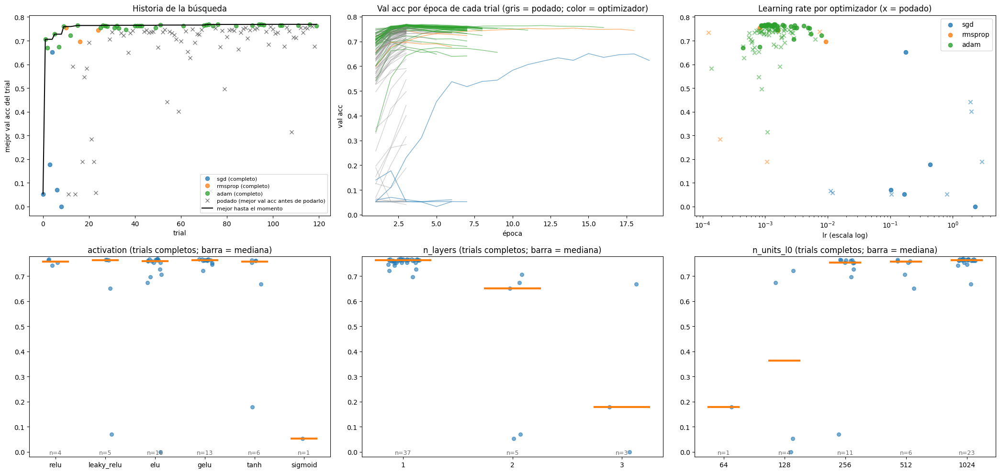

In [ ]:
OPT_COLORS = {"sgd": "C0", "rmsprop": "C1", "adam": "C2"}
fig, axes = plt.subplots(2, 3, figsize=(21, 10))

ax = axes[0, 0]
for opt_name, c in OPT_COLORS.items():
    s = done[done.optimizer == opt_name]
    ax.plot(s["number"], s["value"], "o", color=c, alpha=0.75, label=f"{opt_name} (completo)")
pv = [max(t.intermediate_values.values()) if t.intermediate_values else np.nan for t in study.trials]
pr_idx = pruned["number"].values
ax.plot(pr_idx, np.array(pv)[pr_idx], "x", color="gray", label="podado (mejor val acc antes de podarlo)")
ax.plot(done["number"], np.maximum.accumulate(done["value"].values), color="k", label="mejor hasta el momento")
ax.set_title("Historia de la búsqueda")
ax.set_xlabel("trial")
ax.set_ylabel("mejor val acc del trial")
ax.legend(fontsize=8, loc="lower right")

ax = axes[0, 1]
for t in study.trials:
    iv = t.intermediate_values
    if not iv:
        continue
    color = "gray" if t.state == optuna.trial.TrialState.PRUNED else OPT_COLORS[t.params["optimizer"]]
    ax.plot(list(iv.keys()), t.user_attrs["val_acc_curve"][:len(iv)], color=color, alpha=0.35 if color == "gray" else 0.6, lw=1)
ax.set_title("Val acc por época de cada trial (gris = podado; color = optimizador)")
ax.set_xlabel("época")
ax.set_ylabel("val acc")

ax = axes[0, 2]
for opt_name, c in OPT_COLORS.items():
    s = done[done.optimizer == opt_name]
    ax.scatter(s["lr"], s["value"], color=c, alpha=0.8, label=opt_name)
    s = pruned[pruned.optimizer == opt_name]
    ax.scatter(s["lr"], np.array(pv)[s["number"].values], color=c, marker="x", alpha=0.5)
ax.set_xscale("log")
ax.set_title("Learning rate por optimizador (x = podado)")
ax.set_xlabel("lr (escala log)")
ax.legend()

rng = np.random.default_rng(0)
for ax, (p, levels) in zip([axes[1, 0], axes[1, 1], axes[1, 2]], [cat_params[1], cat_params[2], cat_params[3]]):
    for i, lv in enumerate(levels):
        v = done.loc[done[p] == lv, "value"].values
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, color="C0", alpha=0.6, s=30)
        if len(v):
            ax.plot([i - 0.25, i + 0.25], [np.median(v)] * 2, color="C1", lw=3)
        ax.text(i, done.value.min() - 0.01, f"n={len(v)}", ha="center", fontsize=9, color="dimgray")
    ax.set_xticks(range(len(levels)))
    ax.set_xticklabels([str(l) for l in levels])
    ax.set_ylim(done.value.min() - 0.02, done.value.max() + 0.01)
    ax.set_title(f"{p} (trials completos; barra = mediana)")
plt.tight_layout()
plt.show()

### Qué encontró Optuna

La búsqueda terminó con 45 trials completos y 75 podados. La mejor prueba fue la **95**, con **0.7689** de accuracy de validación en la época 3. Su configuración es:

- **Preprocesamiento:** sin stopwords, lematización, unigramas, `max_features=40000` y `min_df=1`.
- **Arquitectura:** una capa oculta de 1024 unidades con ELU y dropout 0.08, sin weight decay.
- **Optimizador:** Adam con $\eta = 1.14\cdot10^{-3}$, $\beta_1 = 0.746$ y $\beta_2 = 0.911$, batch 256.

Para dimensionar las diferencias: con 2.263 documentos de validación, el error estándar de una accuracy de 0.77 es $\sqrt{0.77\cdot0.23/2263}\approx0.009$, así que diferencias menores a un punto no son significativas. Hay 27 trials completos a menos de un punto del mejor.

Las 10 mejores pruebas son casi iguales entre sí:

- todas usan Adam, una capa oculta, unigramas, 40.000 términos y `min_df=1`;
- 9 de 10 tienen 1024 unidades, un learning rate entre $9.7\cdot10^{-4}$ y $1.9\cdot10^{-3}$ y dropout entre 0 y 0.10;
- el batch es de 128 o 256;
- la activación varía entre ELU, GELU, ReLU y Leaky ReLU, y no se nota en el resultado.

Las medianas por valor no son comparaciones controladas: Optuna prueba más lo que funciona (101 trials con Adam contra 12 con SGD) y cada mediana mezcla el efecto del resto de los hiperparámetros. Con esa salvedad:

- **Optimizador.** Adam tiene una mediana de 0.763 sobre 37 trials completos y RMSProp 0.744 sobre 3. SGD fracasó en la búsqueda: de sus 12 trials, 7 fueron podados, y de los 5 completos 4 quedaron por debajo de 0.18. El #8, con $\eta=2.26$ y 3 capas, divergió en la primera época y quedó registrado con 0. Solo el #4 aprendió (0.651). El rango de learning rate de SGD es amplio y solo una franja angosta funciona. La sección 5 D lo compara ajustado por separado.
- **Profundidad.** Una capa oculta da una mediana de 0.763 (37 completos), dos capas 0.651 (5) y tres 0.178 (3). Como TPE dejó de proponer redes profundas, la comparación justa está en la sección 5 B.
- **Activación.** Todas quedan entre 0.759 y 0.764 salvo la sigmoide (0.053, un solo trial completo, que además usaba SGD, y 3 podados).
- **Ancho de la primera capa.** 256, 512 y 1024 unidades dan 0.754, 0.757 y 0.763. Las medianas bajas de 64 y 128 (0.178 y 0.364) salen de pocos trials completos con SGD o con varias capas, no del ancho.
- **Batch size.** Domina el batch grande: 128 (0.762) y 256 (0.763), contra 0.745 con 32.
- **Regularización.** Los trials sin weight decay tienen mediana 0.763 (40 completos) y los que lo usan 0.674 (5). Los mejores trials tienen dropout casi nulo.
- **Preprocesamiento.** Unigramas (0.762) claramente por encima de bigramas (0.689; 14 de los 16 trials con bigramas fueron podados). Lematizar (0.764) queda apenas por encima de stemming y de no normalizar (0.755); sacar stopwords (0.764), apenas por encima de no hacerlo (0.760). Estas dos últimas diferencias son menores que el error estándar. **El vocabulario más grande es el mejor:** 0.763 con 40.000 términos, contra 0.733 con 20.000. Igual que en el TP1, el mejor valor quedó en el máximo del rango probado.

**Importancia fANOVA.** A nivel global, el optimizador explica 0.62 de la variación entre trials completos. Ese valor sale de los fracasos de SGD, no de diferencias entre Adam y RMSProp. Dentro de los 37 trials completos con Adam, los más importantes son el tamaño del vocabulario (0.25), $\beta_2$ (0.24), la cantidad de capas (0.18), el learning rate (0.11) y si se usa weight decay (0.10). fANOVA solo mide la variación dentro de los valores que se probaron, y TPE concentró los trials de Adam en la zona que funciona. Para SGD y RMSProp no hay suficientes trials completos como para que la importancia sea confiable.

### 4.2 Pruning: la misma búsqueda con y sin pruning

Para medir el efecto del pruning se repite la búsqueda completa **sin pruner**: mismo espacio, misma semilla del sampler, misma cantidad de trials y mismo early stopping dentro de cada trial. Lo único que cambia es que ningún trial se corta por comparación con los demás. Se comparan el tiempo total, las épocas entrenadas y la mejor accuracy de validación alcanzada, y cómo evoluciona la mejor accuracy en función del tiempo de búsqueda.

Las dos búsquedas no prueban exactamente las mismas configuraciones: TPE decide cada trial según los resultados anteriores, y sin pruning tiene más trials completos de los que aprender. La comparación es entre dos búsquedas con el mismo presupuesto de trials, que es la decisión práctica que hay que tomar.

,con pruning,sin pruning
trials completos,45,120
trials podados,75,0
épocas entrenadas,595,1361
seg entrenando,427,665
seg totales de la búsqueda,618,803
mejor val acc,0.7689,0.7751
trials a < 1 punto del mejor,27,31


Ahorro de tiempo total por el pruning: 23% | épocas: 595 contra 1361 (máximo posible 2400)
Época en la que se podaron los trials: {3: 64, 4: 4, 5: 4, 6: 2, 7: 1}
Trials podados por optimizer: {'adam': '64/101', 'rmsprop': '4/7', 'sgd': '7/12'}
Trials podados por activation: {'elu': '22/38', 'gelu': '23/36', 'leaky_relu': '9/14', 'relu': '6/10', 'sigmoid': '3/4', 'tanh': '12/18'}
Trials podados por n_layers: {1: '61/98', 2: '12/17', 3: '2/5'}
Trials podados por ngram_range: {'1_2gram': '14/16', '1gram': '61/104'}
Reparto del tiempo de los trials (con pruning): vectorizar 15% | pasar a tensor 1% | entrenar 84%


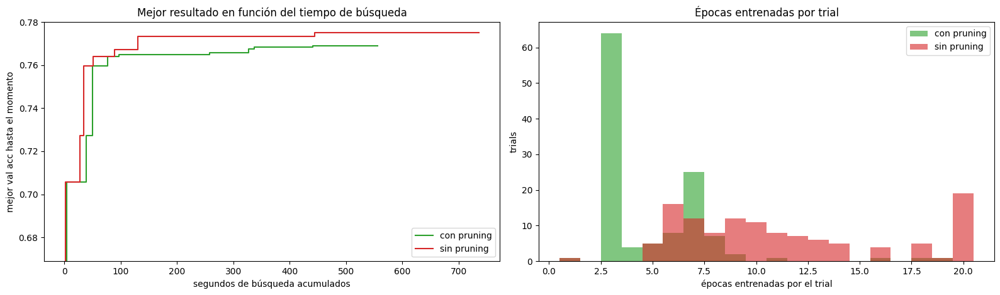

In [ ]:
study_np = run_study("busqueda_sin_pruning", make_objective(tag="noprune"), N_TRIALS, prune=False)
FINISHED = (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)


def search_summary(st):
    ts = [t for t in st.trials if t.state in FINISHED]
    vals = [t.value for t in ts if t.state == optuna.trial.TrialState.COMPLETE]
    return {"trials completos": len(vals), "trials podados": len(ts) - len(vals),
            "épocas entrenadas": sum(t.user_attrs["epochs_run"] for t in ts),
            "seg entrenando": sum(t.user_attrs["t_train"] for t in ts),
            "seg totales de la búsqueda": st.user_attrs["seconds"],
            "mejor val acc": max(vals), "trials a < 1 punto del mejor": sum(v >= max(vals) - 0.01 for v in vals)}


cmp = pd.DataFrame({"con pruning": search_summary(study), "sin pruning": search_summary(study_np)})
display(cmp.style.format("{:.4f}", subset=pd.IndexSlice[["mejor val acc"], :])
        .format("{:.0f}", subset=pd.IndexSlice[[i for i in cmp.index if i != "mejor val acc"], :]))
ahorro = 1 - cmp.loc["seg totales de la búsqueda", "con pruning"] / cmp.loc["seg totales de la búsqueda", "sin pruning"]
print(f"Ahorro de tiempo total por el pruning: {ahorro:.0%} | "
      f"épocas: {cmp.loc['épocas entrenadas', 'con pruning']:.0f} contra {cmp.loc['épocas entrenadas', 'sin pruning']:.0f} "
      f"(máximo posible {MAX_EPOCHS_SEARCH * N_TRIALS})")
print(f"Época en la que se podaron los trials: {pruned['epochs_run'].value_counts().sort_index().to_dict()}")
for p in ["optimizer", "activation", "n_layers", "ngram_range"]:
    frac = df_trials.groupby(p)["state"].apply(lambda s: f"{(s == 'PRUNED').sum()}/{len(s)}")
    print(f"Trials podados por {p}: {frac.to_dict()}")
tt = df_trials[["t_vectorize", "t_tensor", "t_train"]].sum()
print(f"Reparto del tiempo de los trials (con pruning): vectorizar {tt.t_vectorize / tt.sum():.0%} | "
      f"pasar a tensor {tt.t_tensor / tt.sum():.0%} | entrenar {tt.t_train / tt.sum():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for st, label, c in [(study, "con pruning", "C2"), (study_np, "sin pruning", "C3")]:
    dur = np.array([t.duration.total_seconds() for t in st.trials])
    val = np.array([t.value if t.state == optuna.trial.TrialState.COMPLETE else -np.inf for t in st.trials])
    axes[0].step(np.cumsum(dur), np.maximum.accumulate(val), where="post", color=c, label=label)
    axes[1].hist([t.user_attrs["epochs_run"] for t in st.trials if t.state in FINISHED], bins=np.arange(0.5, MAX_EPOCHS_SEARCH + 1.5),
                 alpha=0.6, color=c, label=label)
axes[0].set_xlabel("segundos de búsqueda acumulados")
axes[0].set_ylabel("mejor val acc hasta el momento")
axes[0].set_ylim(max(0.5, study.best_value - 0.1), max(study.best_value, study_np.best_value) + 0.005)
axes[0].set_title("Mejor resultado en función del tiempo de búsqueda")
axes[1].set_xlabel("épocas entrenadas por el trial")
axes[1].set_ylabel("trials")
axes[1].set_title("Épocas entrenadas por trial")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

### Análisis del pruning

| | Con pruning | Sin pruning |
|---|---|---|
| Trials completos / podados | 45 / 75 | 120 / 0 |
| Épocas entrenadas (máximo posible: 2400) | 595 | 1361 |
| Segundos entrenando | 427 | 665 |
| Segundos totales de la búsqueda | 618 | 803 |
| Mejor accuracy de validación | 0.7689 | **0.7751** |
| Trials a menos de 1 punto del mejor | 27 | 31 |

**Lo que ahorra.** El pruning entrenó un 56 % menos de épocas y un 36 % menos de tiempo de entrenamiento, pero el tiempo total de la búsqueda bajó solo un 23 %. Las dos diferencias tienen explicación:

- Lo que se poda son sobre todo modelos chicos o que fallan: la mediana de parámetros de los trials podados es la mitad que la de los completos (10 millones contra 20), así que sus épocas son más baratas.
- Cada trial tiene un costo fijo que el pruning no evita: vectorizar (15 % del tiempo de los trials), pasar a tensor y registrar en MLflow.

64 de los 75 trials podados se cortaron en la época 3, la primera en la que el pruner puede actuar. Lo que más se podó fueron los bigramas (14 de 16), la sigmoide (3 de 4) y SGD (7 de 12).

**El resultado.** En esta comparación, el pruning no dio ventaja en calidad. En el gráfico de la izquierda, la búsqueda sin pruning tiene en todo momento un resultado igual o mejor: a los 130 s llega a 0.773, que la búsqueda con pruning no alcanza. La diferencia final (0.7689 contra 0.7751) es menor que el error estándar (0.9 puntos) y sale de una sola comparación entre dos búsquedas, así que no permite afirmar que el pruning empeore el resultado. Solo permite afirmar que, en este caso, no lo mejoró.

**Un riesgo conocido del criterio.** `MedianPruner` compara en cada época la mejor accuracy alcanzada hasta ahí contra la mediana de los trials anteriores, así que poda lo que **arranca** lento, no lo que termina mal. En este problema hay configuraciones buenas que aprenden despacio. Los mejores trials de la búsqueda de Adam ($\eta=2.3\cdot10^{-4}$) y de la búsqueda de 1 capa ($\eta=4\cdot10^{-4}$) llegan a su máximo en la época 15, mientras que el mejor de la búsqueda principal ($\eta=1.1\cdot10^{-3}$) llega en la 3. Configuraciones así están por debajo de la mediana en la época 3 y pueden quedar podadas. Pero esas búsquedas también usaban pruning y las encontraron igual: el pruner las deja pasar cuando los demás trials de la búsqueda tienen learning rates parecidos, como pasa en espacios de búsqueda chicos. Con estos datos no se puede atribuir la diferencia entre las dos búsquedas principales a este mecanismo.

**Conclusión.** El pruning redujo el costo de la búsqueda (−56 % de épocas, −23 % de tiempo total) sin una pérdida de calidad significativa, pero tampoco la mejoró. La ganancia de tiempo es moderada porque cada trial ya es corto (~5 s) y tiene costos fijos que no se podan. El pruning rinde más cuando los trials son largos y cuando las primeras épocas predicen bien el resultado final.

## 5. Experimentos controlados

La búsqueda de Optuna mezcla todos los hiperparámetros a la vez y prueba más veces lo que parece prometedor, así que sus medianas no son comparaciones controladas. Para aislar cada efecto se usan el mismo split, la misma semilla y `EPOCHS_DYN` épocas sin early stopping, para ver también qué pasa después del mejor punto. Después de cada época se mide loss y accuracy de train (en modo `eval`, sin dropout) y de validación.

El tipo de comparación depende de qué se estudia:

- **A. Activación** y **C. Ancho** (una capa oculta de 16 a 4096 unidades): se parte de la mejor configuración de Optuna y se cambia solo ese aspecto.
- **B. Profundidad** (0 a 3 capas ocultas) y **D. Optimizador**: cambiar la cantidad de capas o el optimizador cambia qué learning rate, regularización y momentos funcionan, así que usar los de la mejor configuración favorecería a esa configuración. Por eso cada profundidad y cada optimizador tienen **su propia búsqueda de Optuna**, con el mismo presupuesto, y se comparan los mejores de cada una. En D, además, se varían los momentos de orden 1 y 2 alrededor de la configuración ajustada de cada optimizador, manteniendo constante el paso efectivo.
- **E. Sobreajuste**: barrido de capas × unidades con una misma configuración neutra, sin regularización.
- **F. Regularización** de la configuración sobreajustada.

Todo se registra en TensorBoard (`runs/dynamics/`) y en MLflow.

In [ ]:
EPOCHS_DYN = 3 if MODO_RAPIDO else 30
BEST_CFG = study.best_trial.user_attrs["cfg"]
print("Configuración de referencia (mejor trial):", BEST_CFG)
X_tr_b, X_val_b, _, _ = get_split_data(BEST_CFG)
DATA_B = (X_tr_b, X_val_b)
print(f"Vocabulario: {X_tr_b.shape[1]} términos")

dyn = {}       # dyn[grupo][nombre] = historia
trained = {}   # clave de la configuración -> historia (no entrenar dos veces la misma corrida)


def cfg_key(cfg):
    return tuple(sorted((k, tuple(v) if isinstance(v, list) else v) for k, v in cfg.items()))


def run_group(group, configs, epochs=None):
    epochs = epochs or EPOCHS_DYN
    dyn[group] = {}
    for name, cfg in configs.items():
        key = (cfg_key(cfg), epochs)
        if key in trained:
            dyn[group][name] = trained[key]
            print(f"[{group}] {name:34s} misma corrida que en un grupo anterior: se reutiliza")
            continue
        slug = "".join(ch if ch.isalnum() or ch in "._-=" else "_" for ch in name)
        writer = SummaryWriter(f"runs/dynamics/{group}/{slug}")
        _, h = train_mlp(cfg, X_tr_b, y_tr_t, X_val_b, y_val_t, epochs=epochs, writer=writer)
        writer.close()
        h["cfg"] = cfg
        dyn[group][name] = trained[key] = h
        with mlflow.start_run(run_name=f"dyn_{group}_{slug}"):
            mlflow.log_params({k: str(v) for k, v in cfg.items()})
            for ep in range(h["epochs_run"]):
                mlflow.log_metrics({k: float(h[k][ep]) for k in ["train_loss", "train_acc", "val_loss", "val_acc"]
                                    if np.isfinite(h[k][ep])}, step=ep + 1)
            mlflow.log_metrics({"best_val_acc": h["best_val_acc"], "best_epoch": h["best_epoch"], "n_params": h["n_params"]})
        vl = np.array(h["val_loss"])
        print(f"[{group}] {name:34s} mejor val acc {h['best_val_acc']:.4f} (ép. {h['best_epoch']:2d}) | final: val acc "
              f"{h['val_acc'][-1]:.4f}, train acc {h['train_acc'][-1]:.3f}, val loss {vl[-1]:.3f} (mín {np.nanmin(vl):.3f} "
              f"ép. {int(np.nanargmin(vl)) + 1}) | {h['n_params']:,} params | {np.mean(h['epoch_time']):.2f} s/época"
              + ("" if h["status"] == "completed" else f" | {h['status']}"))


def plot_group(group, title, ordered=False):
    runs = dyn[group]
    colors = plt.cm.viridis(np.linspace(0, 0.85, len(runs))) if ordered else [f"C{i}" for i in range(len(runs))]
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    panels = [("train_loss", "Loss de train"), ("val_loss", "Loss de validación"),
              ("train_acc", "Accuracy de train"), ("val_acc", "Accuracy de validación")]
    for ax, (k, t) in zip(axes, panels):
        for (name, h), c in zip(runs.items(), colors):
            ax.plot(range(1, len(h[k]) + 1), h[k], color=c, label=name)
        ax.set_title(t)
        ax.set_xlabel("época")
    axes[0].set_yscale("log")
    axes[1].set_yscale("log")
    if "MAX_ACC_TR" in globals():
        axes[2].axhline(MAX_ACC_TR, color="gray", ls="--", lw=1)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=min(len(labels), 6), bbox_to_anchor=(0.5, 1.10), frameon=False)
    fig.suptitle(title, y=1.17, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


REF = "referencia (mejor de Optuna)"

Configuración de referencia (mejor trial): {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 40000, 'min_df': 1, 'batch_size': 256, 'optimizer': 'adam', 'hidden': [1024], 'activation': 'elu', 'dropout': 0.07613861387437061, 'weight_decay': 0.0, 'lr': 0.0011421945891596733, 'beta1': 0.7462539715436266, 'beta2': 0.9108207582826973}
Vocabulario: 40000 términos


### 5.0 Documentos que ningún modelo puede separar

Antes de comparar modelos conviene saber cuál es la máxima accuracy posible en train. Algunos documentos quedan con el vector TF-IDF en cero (no tienen ningún término del vocabulario después del preprocesamiento) y otros comparten exactamente el mismo vector con documentos de otra clase. A todos los documentos con un mismo vector cualquier modelo les asigna la misma predicción, así que lo mejor posible es acertar la clase mayoritaria de cada grupo de vectores idénticos. La celda calcula esa cota con el preprocesamiento de la referencia; en los gráficos de la sección 5 aparece como una línea gris punteada en el panel de accuracy de train.

In [ ]:
from collections import Counter, defaultdict


def separability(X, y):
    """Documentos con vector nulo, cantidad de vectores distintos y accuracy máxima alcanzable con esos vectores."""
    X = X.tocsr().copy()
    X.sort_indices()
    groups = defaultdict(Counter)
    for i in range(X.shape[0]):
        a, b = X.indptr[i], X.indptr[i + 1]
        groups[(X.indices[a:b].tobytes(), X.data[a:b].tobytes())][y[i]] += 1
    empty = np.diff(X.indptr) == 0
    max_acc = sum(c.most_common(1)[0][1] for c in groups.values()) / len(y)
    return empty, len(groups), max_acc


X_tr_sp, _ = _sparse_cache[tuple(BEST_CFG[k] for k in PREPRO_KEYS)]
empty_tr, n_distinct, MAX_ACC_TR = separability(X_tr_sp, y_tr_s)
print(f"Train de búsqueda: {len(y_tr_s)} documentos | con vector nulo: {empty_tr.sum()} ({empty_tr.mean():.1%}) | "
      f"vectores distintos: {n_distinct}")
print(f"Accuracy máxima alcanzable en train: {MAX_ACC_TR:.4f}")
print("Clases más frecuentes entre los documentos vacíos:",
      {class_names[k]: v for k, v in Counter(y_tr_s[empty_tr]).most_common(3)})

Train de búsqueda: 9051 documentos | con vector nulo: 254 (2.8%) | vectores distintos: 8760
Accuracy máxima alcanzable en train: 0.9743
Clases más frecuentes entre los documentos vacíos: {'rec.autos': 29, 'rec.sport.baseball': 21, 'comp.os.ms-windows.misc': 20}


[act] relu                               mejor val acc 0.7702 (ép.  4) | final: val acc 0.7375, train acc 0.974, val loss 1.290 (mín 0.821 ép. 6) | 40,981,524 params | 0.86 s/época
[act] leaky_relu                         mejor val acc 0.7707 (ép.  4) | final: val acc 0.7362, train acc 0.974, val loss 1.291 (mín 0.821 ép. 5) | 40,981,524 params | 0.86 s/época
[act] referencia (mejor de Optuna)       mejor val acc 0.7689 (ép.  3) | final: val acc 0.7375, train acc 0.974, val loss 1.338 (mín 0.818 ép. 5) | 40,981,524 params | 0.86 s/época
[act] gelu                               mejor val acc 0.7667 (ép.  4) | final: val acc 0.7397, train acc 0.974, val loss 1.293 (mín 0.812 ép. 6) | 40,981,524 params | 0.86 s/época
[act] tanh                               mejor val acc 0.7689 (ép.  3) | final: val acc 0.7384, train acc 0.974, val loss 1.344 (mín 0.819 ép. 5) | 40,981,524 params | 0.86 s/época
[act] sigmoid                            mejor val acc 0.7640 (ép. 27) | final: val acc 0.7578,

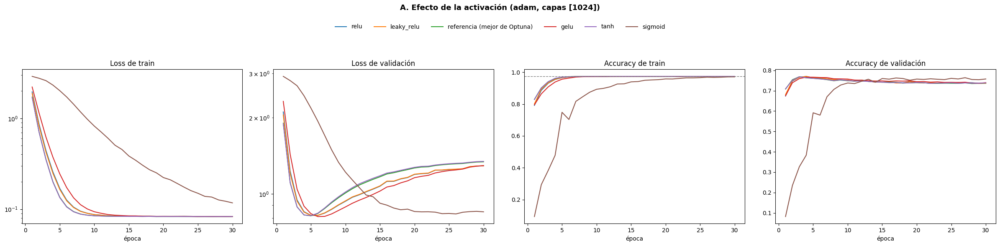

In [ ]:
# A. Función de activación
run_group("act", {(REF if a == BEST_CFG["activation"] else a): {**BEST_CFG, "activation": a} for a in ACTIVATIONS})
plot_group("act", f"A. Efecto de la activación ({BEST_CFG['optimizer']}, capas {BEST_CFG['hidden']})")

### Análisis A: activación

La referencia es la mejor configuración de la búsqueda principal: una capa de 1024 unidades, dropout 0.08, Adam con $\eta=1.14\cdot10^{-3}$ y batch 256.

| Activación | Mejor val acc | Época | Val acc final (30) | Val loss mín → final |
|---|---|---|---|---|
| ReLU | 0.7702 | 4 | 0.7375 | 0.821 → 1.290 |
| Leaky ReLU | 0.7707 | 4 | 0.7362 | 0.821 → 1.291 |
| ELU (referencia) | 0.7689 | 3 | 0.7375 | 0.818 → 1.338 |
| GELU | 0.7667 | 4 | 0.7397 | 0.812 → 1.293 |
| tanh | 0.7689 | 3 | 0.7384 | 0.819 → 1.344 |
| sigmoide | 0.7640 | 27 | 0.7578 | 0.832 → 0.848 |

**ReLU, Leaky ReLU, ELU, GELU y tanh son equivalentes.** Sus máximos difieren en 0.4 puntos, menos que el error estándar (~0.9). Con una sola capa oculta, cualquier no linealidad razonable sirve. Todas siguen el mismo patrón:

- llegan al máximo en las épocas 3 o 4 y la accuracy de train llega al techo (línea gris punteada, sección 5.0);
- después la validación cae unos 3 puntos y la loss de validación sube un 60 % desde su mínimo.

La activación no cambia el costo: todas tardan 0.86 s por época, porque el tiempo está en las multiplicaciones de matrices.

**La sigmoide aprende mucho más lento.** Llega a 0.7640 recién en la época 27 y su loss de validación casi no sube (0.832 → 0.848), así que al final de las 30 épocas es la de mejor accuracy (0.7578). Su derivada es como máximo 0.25 y sus salidas no están centradas en cero, por lo que el gradiente que llega a la primera capa es varias veces menor que con tanh, cuya derivada vale 1 en el origen. Eso la hace lenta y, como efecto lateral, también tarda en sobreajustar. Con una capa, el efecto es solo lentitud. Con varias capas, el factor $\le 0.25$ se multiplica una vez por capa, así que el gradiente que llega a las primeras capas se atenúa de forma geométrica; ese es el problema del gradiente que se desvanece. Este experimento usa una sola capa, así que no lo mide.

capas ocultas,completos,podados,mejor val acc,época,trials a < 1 punto,arquitectura,activación,dropout,weight decay,lr,β1,β2,batch,params,seg búsqueda
0,23,7,0.7565,6,16,—,—,0.00,0.0e+00,8.30e-03,0.869,0.9795,64,"800,020",87
1,20,10,0.7711,15,10,1024,gelu,0.09,0.0e+00,4.00e-04,0.663,0.9114,256,"40,981,524",269
2,17,13,0.7552,2,5,512-512,tanh,0.25,2.5e-05,2.03e-03,0.782,0.9396,256,"20,753,428",212
3,25,5,0.7221,15,7,1024-64-128,tanh,0.18,0.0e+00,1.45e-03,0.772,0.9209,32,"41,037,524",507


[depth] 0 capas ocultas (softmax)          mejor val acc 0.7565 (ép.  6) | final: val acc 0.7265, train acc 0.974, val loss 1.054 (mín 0.889 ép. 12) | 800,020 params | 0.21 s/época
[depth] 1 capas ocultas                    mejor val acc 0.7711 (ép. 15) | final: val acc 0.7556, train acc 0.973, val loss 0.905 (mín 0.810 ép. 17) | 40,981,524 params | 0.86 s/época
[depth] 2 capas ocultas                    mejor val acc 0.7552 (ép.  2) | final: val acc 0.6748, train acc 0.974, val loss 1.702 (mín 0.874 ép. 2) | 20,753,428 params | 0.49 s/época
[depth] 3 capas ocultas                    mejor val acc 0.7256 (ép. 29) | final: val acc 0.7247, train acc 0.974, val loss 1.436 (mín 1.090 ép. 2) | 41,037,524 params | 4.30 s/época


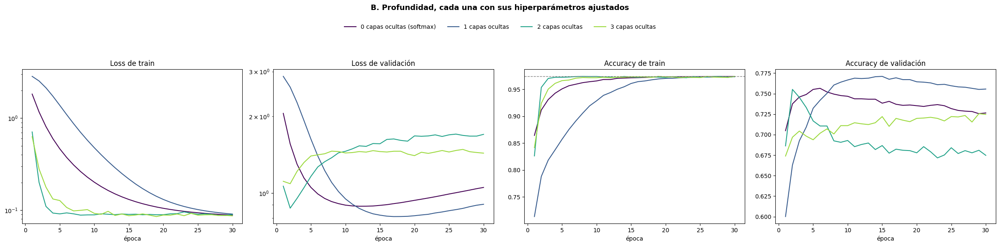

In [ ]:
# B. Profundidad: una búsqueda de Optuna por cantidad de capas ocultas, con el preprocesamiento de la referencia fijo
N_TRIALS_DEPTH = 4 if MODO_RAPIDO else 30
FIXED_PREPRO = {k: BEST_CFG[k] for k in PREPRO_KEYS}


def suggest_depth(L):
    def suggest(trial):
        trial.suggest_categorical("batch_size", [32, 64, 128, 256])
        for i in range(L):
            trial.suggest_categorical(f"n_units_l{i}", UNITS)
        if L > 0:
            trial.suggest_categorical("activation", list(ACTIVATIONS))
        suggest_regularization(trial, dropout=L > 0)
        suggest_optimizer_params(trial, "adam")
    return suggest


depth_studies = {}
for L in [0, 1, 2, 3]:
    depth_studies[L] = run_study(f"profundidad_{L}", make_objective({**FIXED_PREPRO, "n_layers": L, "optimizer": "adam"},
                                                                    suggest_depth(L), tag=f"depth{L}"),
                                 N_TRIALS_DEPTH, n_startup=10)

rows = []
for L, st in depth_studies.items():
    t = st.best_trial
    c = t.user_attrs["cfg"]
    s = search_summary(st)
    rows.append({"capas ocultas": L, "completos": s["trials completos"], "podados": s["trials podados"],
                 "mejor val acc": t.value, "época": t.user_attrs["best_epoch"],
                 "trials a < 1 punto": s["trials a < 1 punto del mejor"],
                 "arquitectura": "-".join(map(str, c["hidden"])) or "—", "activación": c["activation"] if L else "—",
                 "dropout": c["dropout"], "weight decay": c["weight_decay"], "lr": c["lr"], "β1": c["beta1"], "β2": c["beta2"],
                 "batch": c["batch_size"], "params": t.user_attrs["n_params"], "seg búsqueda": st.user_attrs["seconds"]})
df_depth = pd.DataFrame(rows)
display(df_depth.style.format({"mejor val acc": "{:.4f}", "dropout": "{:.2f}", "weight decay": "{:.1e}", "lr": "{:.2e}",
                               "β1": "{:.3f}", "β2": "{:.4f}", "params": "{:,.0f}", "seg búsqueda": "{:.0f}"}).hide(axis="index"))

run_group("depth", {f"{L} capas ocultas" + (" (softmax)" if L == 0 else ""): depth_studies[L].best_trial.user_attrs["cfg"]
                    for L in [0, 1, 2, 3]})
plot_group("depth", "B. Profundidad, cada una con sus hiperparámetros ajustados", ordered=True)

### Análisis B: profundidad

Cada profundidad tuvo su propia búsqueda de 30 trials con el preprocesamiento de la referencia. Se buscaron la arquitectura, la activación, la regularización, el batch y los hiperparámetros de Adam.

| Capas ocultas | Mejor val acc | Época | Arquitectura | Configuración | Trials a < 1 punto | Val acc final (30 ép.) | s/época |
|---|---|---|---|---|---|---|---|
| 0 (softmax) | 0.7565 | 6 | — | $\eta=8.3\cdot10^{-3}$, batch 64 | 16 | 0.7265 | 0.21 |
| 1 | **0.7711** | 15 | 1024 | GELU, dropout 0.09, $\eta=4\cdot10^{-4}$, batch 256 | 10 | 0.7556 | 0.86 |
| 2 | 0.7552 | 2 | 512-512 | tanh, dropout 0.25, weight decay $2.5\cdot10^{-5}$, $\eta=2\cdot10^{-3}$ | 5 | 0.6748 | 0.49 |
| 3 | 0.7221 | 15 | 1024-64-128 | tanh, dropout 0.18, $\eta=1.45\cdot10^{-3}$, batch 32 | 7 | 0.7247 | 4.30 |

Con cada profundidad en su mejor configuración:

- **1 capa** supera a la regresión softmax por 1.5 puntos;
- **2 capas** quedan al nivel de la softmax (−0.1);
- **3 capas** quedan 3.4 puntos por debajo.

Al reentrenar 30 épocas sin early stopping, cada profundidad repite prácticamente su resultado de la búsqueda. La de 3 capas sube de 0.7221 a 0.7256 porque sigue mejorando lentamente hasta la época 29, pero esa diferencia (0.35 puntos) no cambia el orden. La grilla de la sección 5 E muestra lo mismo con otra metodología: con una configuración común para todas las redes, 1 capa supera a 2 y a 3 con cualquier ancho.

**Por qué más capas no ayudan.** Las tres redes con capas ocultas llegan al mismo techo de train, así que memorizan lo mismo; la diferencia está en cómo generalizan. Con una capa, cada unidad oculta es una combinación de palabras y los logits combinan esas unidades. Con más capas, la red puede construir reglas más específicas, combinaciones de combinaciones, y con 9.051 documentos esas reglas terminan describiendo documentos particulares de train en lugar de temas. La red de 2 capas lo muestra en las curvas: llega a su máximo en la época 2 y después su loss de validación se duplica (0.874 → 1.702). El problema ya es casi linealmente separable en el espacio TF-IDF (la softmax ajustada llega al techo de train) y la información que separa los temas está sobre todo en qué palabras aparecen. Una capa agrega las combinaciones útiles; más capas solo agregan formas de memorizar.

**Tiempo.** El costo por época depende más del batch que de la profundidad: la red de 3 capas tarda 4.3 s por época porque su mejor configuración usa batch 32 (283 pasos por época), y la de 2 capas tarda 0.49 s con batch 256.

[width] 1 capa de 16                       mejor val acc 0.7494 (ép. 30) | final: val acc 0.7494, train acc 0.952, val loss 0.884 (mín 0.884 ép. 30) | 640,356 params | 0.07 s/época
[width] 1 capa de 64                       mejor val acc 0.7623 (ép. 14) | final: val acc 0.7490, train acc 0.974, val loss 0.944 (mín 0.826 ép. 17) | 2,561,364 params | 0.08 s/época
[width] 1 capa de 256                      mejor val acc 0.7693 (ép.  7) | final: val acc 0.7393, train acc 0.974, val loss 1.207 (mín 0.810 ép. 9) | 10,245,396 params | 0.23 s/época
[width] 1 capa de 1024                     misma corrida que en un grupo anterior: se reutiliza
[width] 1 capa de 4096                     mejor val acc 0.7662 (ép.  2) | final: val acc 0.7366, train acc 0.974, val loss 1.328 (mín 0.830 ép. 3) | 163,926,036 params | 3.35 s/época


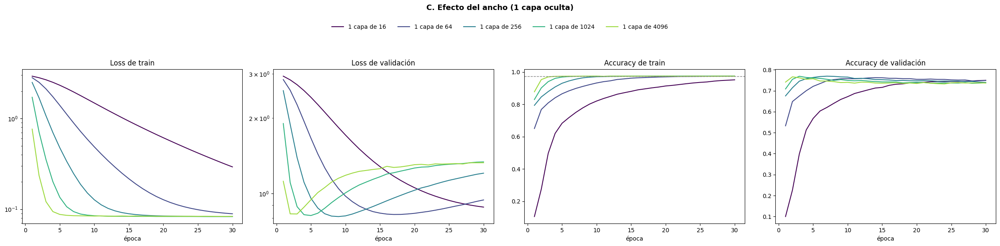

In [ ]:
# C. Ancho: una capa oculta
widths = [16, 64] if MODO_RAPIDO else [16, 64, 256, 1024, 4096]
run_group("width", {f"1 capa de {w}": {**BEST_CFG, "hidden": [w]} for w in widths})
plot_group("width", "C. Efecto del ancho (1 capa oculta)", ordered=True)

### Análisis C: ancho

| 1 capa de | Parámetros | Mejor val acc | Época | Val acc final | Val loss final | s/época |
|---|---|---|---|---|---|---|
| 16 | 640.356 | 0.7494 | 30 | 0.7494 | 0.884 | 0.07 |
| 64 | 2.561.364 | 0.7623 | 14 | 0.7490 | 0.944 | 0.08 |
| 256 | 10.245.396 | 0.7693 | 7 | 0.7393 | 1.207 | 0.23 |
| 1024 (referencia) | 40.981.524 | 0.7689 | 3 | 0.7375 | 1.338 | 0.86 |
| 4096 | 163.926.036 | 0.7662 | 2 | 0.7366 | 1.328 | 3.35 |

A partir de 64 unidades, el **máximo** casi no depende del ancho: queda entre 0.762 y 0.769, dentro del error estándar. Con 16 unidades la red sigue aprendiendo a la época 30 (0.952 en train) y se queda en 0.749. Es un cuello de botella que aprende lento, pero tampoco sobreajusta: la loss de validación es mínima en la última época.

El ancho sí cambia dos cosas:

1. **Cuándo se alcanza el máximo.** Pasa de la época 14 con 64 unidades a la época 2 con 4096. Una capa más ancha tiene más parámetros que se ajustan en cada paso y memoriza el train más rápido.
2. **Cuánto se degrada después.** La loss final de validación crece de 0.88 con 16 unidades a 1.33 con 1024 o 4096, y la accuracy final baja de 0.749 a 0.737. Con más unidades el modelo puede seguir aumentando su confianza sobre el train, y sus errores en validación salen cada vez más caros.

Con early stopping, el ancho casi no importa para la accuracy. Importa para el costo. Con batch 256 hay solo 36 pasos por época, así que el tiempo crece casi en proporción a los parámetros: de 1024 a 4096 unidades los parámetros se multiplican por 4 y el tiempo por 3.9. La red de 4096 unidades tiene 164 millones de parámetros, tarda 42 veces más por época que la de 64 y no da un resultado mejor.

optimizador,completos,podados,mejor val acc,época,lr,paso efectivo lr/(1−μ),momentos,seg búsqueda
sgd,22,3,0.7371,15,1.54e-01,3.13e+00,"momento 0.951, Nesterov True",301
rmsprop,11,14,0.7698,11,1.31e-04,3.05e-04,"α 0.9724, momento 0.571",176
adam,12,13,0.7733,15,2.33e-04,2.33e-04,"β1 0.649, β2 0.9524",177


[opt_cmp] SGD ajustado                       mejor val acc 0.7371 (ép. 15) | final: val acc 0.7300, train acc 0.974, val loss 0.993 (mín 0.943 ép. 13) | 40,981,524 params | 0.71 s/época
[opt_cmp] RMSProp ajustado                   mejor val acc 0.7698 (ép. 11) | final: val acc 0.7503, train acc 0.974, val loss 0.957 (mín 0.819 ép. 16) | 40,981,524 params | 0.86 s/época
[opt_cmp] Adam ajustado                      mejor val acc 0.7733 (ép. 15) | final: val acc 0.7548, train acc 0.973, val loss 0.871 (mín 0.811 ép. 21) | 40,981,524 params | 0.86 s/época


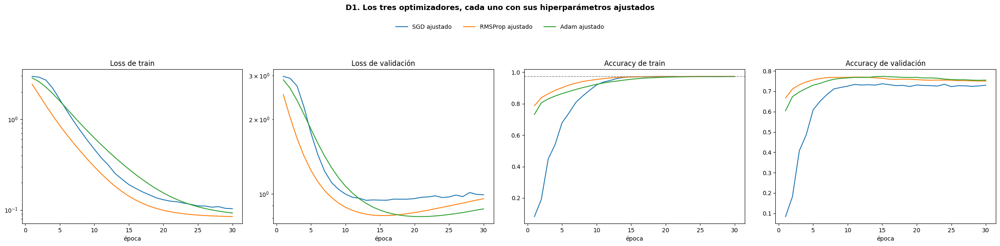

[sgd] SGD ajustado                       misma corrida que en un grupo anterior: se reutiliza
[sgd] sin momento                        mejor val acc 0.3292 (ép.  2) | final: val acc 0.0517, train acc 0.052, val loss 904.528 (mín 2.682 ép. 3) | 40,981,524 params | 0.49 s/época
[sgd] momento 0.9                        mejor val acc 0.7335 (ép. 19) | final: val acc 0.7282, train acc 0.974, val loss 1.030 (mín 0.954 ép. 13) | 40,981,524 params | 0.60 s/época
[sgd] Nesterov 0.9                       mejor val acc 0.7353 (ép. 13) | final: val acc 0.7238, train acc 0.974, val loss 1.037 (mín 0.938 ép. 13) | 40,981,524 params | 0.68 s/época
[sgd] momento 0.9 con el lr de 'sin momento' mejor val acc 0.0530 (ép. 11) | final: val acc 0.0530, train acc 0.053, val loss 2904.891 (mín 1711.882 ép. 25) | 40,981,524 params | 0.60 s/época


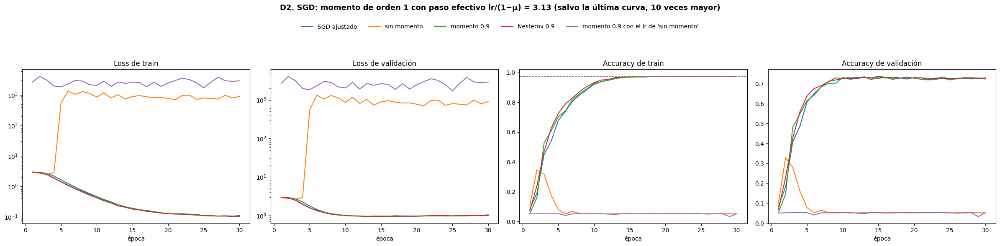

[rmsprop] RMSProp ajustado                   misma corrida que en un grupo anterior: se reutiliza
[rmsprop] α=0.9                              mejor val acc 0.7693 (ép. 15) | final: val acc 0.7539, train acc 0.973, val loss 0.940 (mín 0.811 ép. 17) | 40,981,524 params | 0.86 s/época
[rmsprop] α=0.99                             mejor val acc 0.7684 (ép.  6) | final: val acc 0.7543, train acc 0.974, val loss 0.912 (mín 0.834 ép. 15) | 40,981,524 params | 0.86 s/época
[rmsprop] α=0.999                            mejor val acc 0.7627 (ép.  2) | final: val acc 0.7486, train acc 0.974, val loss 0.930 (mín 0.841 ép. 4) | 40,981,524 params | 0.86 s/época
[rmsprop] sin momento (mismo paso efectivo)  mejor val acc 0.7698 (ép.  9) | final: val acc 0.7499, train acc 0.974, val loss 0.955 (mín 0.819 ép. 16) | 40,981,524 params | 0.73 s/época
[rmsprop] momento 0.9 (mismo paso efectivo)  mejor val acc 0.7702 (ép.  8) | final: val acc 0.7512, train acc 0.974, val loss 0.960 (mín 0.819 ép. 16) | 40,981

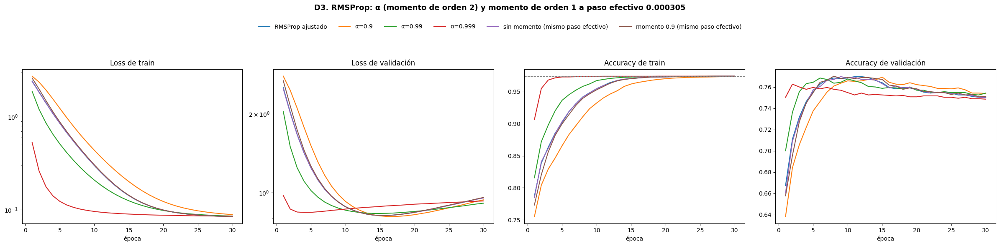

[adam] Adam ajustado                      misma corrida que en un grupo anterior: se reutiliza
[adam] β1=0                               mejor val acc 0.7729 (ép. 15) | final: val acc 0.7552, train acc 0.973, val loss 0.866 (mín 0.811 ép. 21) | 40,981,524 params | 0.86 s/época
[adam] β1=0.9                             mejor val acc 0.7702 (ép. 14) | final: val acc 0.7525, train acc 0.974, val loss 0.889 (mín 0.810 ép. 20) | 40,981,524 params | 0.86 s/época
[adam] β2=0.9                             mejor val acc 0.7711 (ép. 15) | final: val acc 0.7574, train acc 0.973, val loss 0.861 (mín 0.809 ép. 22) | 40,981,524 params | 0.86 s/época
[adam] β2=0.999                           mejor val acc 0.7711 (ép. 10) | final: val acc 0.7565, train acc 0.974, val loss 0.852 (mín 0.850 ép. 27) | 40,981,524 params | 0.86 s/época


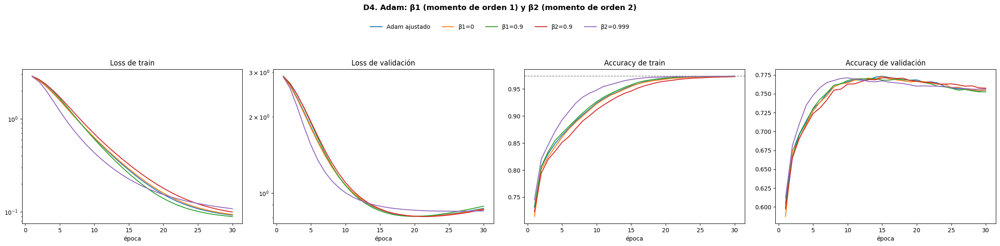

In [ ]:
# D. Optimizadores y momentos.
# D1: una búsqueda por optimizador, con el preprocesamiento, la arquitectura y la regularización de la referencia fijos.
N_TRIALS_OPT = 4 if MODO_RAPIDO else 25
base_params = {k: v for k, v in study.best_params.items() if k not in OPT_KEYS + ["optimizer"]}
opt_studies = {}
for opt_name in ["sgd", "rmsprop", "adam"]:
    opt_studies[opt_name] = run_study(f"optimizador_{opt_name}",
                                      make_objective({**base_params, "optimizer": opt_name},
                                                     lambda t, o=opt_name: suggest_optimizer_params(t, o), tag=f"opt_{opt_name}"),
                                      N_TRIALS_OPT, n_startup=10)
TUNED = {o: st.best_trial.user_attrs["cfg"] for o, st in opt_studies.items()}
rows = []
for o, st in opt_studies.items():
    c, s = TUNED[o], search_summary(st)
    extra = {"sgd": f"momento {c.get('momentum', 0):.3f}, Nesterov {c.get('nesterov')}",
             "rmsprop": f"α {c.get('alpha', 0):.4f}, momento {c.get('momentum', 0):.3f}",
             "adam": f"β1 {c.get('beta1', 0):.3f}, β2 {c.get('beta2', 0):.4f}"}[o]
    rows.append({"optimizador": o, "completos": s["trials completos"], "podados": s["trials podados"],
                 "mejor val acc": st.best_value, "época": st.best_trial.user_attrs["best_epoch"], "lr": c["lr"],
                 "paso efectivo lr/(1−μ)": c["lr"] / (1 - c.get("momentum", 0.0)), "momentos": extra,
                 "seg búsqueda": st.user_attrs["seconds"]})
display(pd.DataFrame(rows).style.format({"mejor val acc": "{:.4f}", "lr": "{:.2e}", "paso efectivo lr/(1−μ)": "{:.2e}",
                                         "seg búsqueda": "{:.0f}"}).hide(axis="index"))

run_group("opt_cmp", {"SGD ajustado": TUNED["sgd"], "RMSProp ajustado": TUNED["rmsprop"], "Adam ajustado": TUNED["adam"]})
plot_group("opt_cmp", "D1. Los tres optimizadores, cada uno con sus hiperparámetros ajustados")


def eff_step(cfg):
    """Paso efectivo de un método con momento de orden 1: lr / (1 − μ)."""
    return cfg["lr"] / (1 - cfg.get("momentum", 0.0))


# D2. SGD: momento de orden 1 manteniendo constante el paso efectivo del SGD ajustado
s_ = TUNED["sgd"]
s_eff = eff_step(s_)
run_group("sgd", {
    "SGD ajustado": s_,
    "sin momento": {**s_, "momentum": 0.0, "nesterov": False, "lr": s_eff},
    "momento 0.9": {**s_, "momentum": 0.9, "nesterov": False, "lr": s_eff * 0.1},
    "Nesterov 0.9": {**s_, "momentum": 0.9, "nesterov": True, "lr": s_eff * 0.1},
    "momento 0.9 con el lr de 'sin momento'": {**s_, "momentum": 0.9, "nesterov": False, "lr": s_eff},
})
plot_group("sgd", f"D2. SGD: momento de orden 1 con paso efectivo lr/(1−μ) = {s_eff:.3g} (salvo la última curva, 10 veces mayor)")

# D3. RMSProp: momento de orden 2 (α) y momento de orden 1 a paso efectivo constante
r_ = TUNED["rmsprop"]
r_eff = eff_step(r_)
run_group("rmsprop", {
    "RMSProp ajustado": r_,
    "α=0.9": {**r_, "alpha": 0.9},
    "α=0.99": {**r_, "alpha": 0.99},
    "α=0.999": {**r_, "alpha": 0.999},
    "sin momento (mismo paso efectivo)": {**r_, "momentum": 0.0, "lr": r_eff},
    "momento 0.9 (mismo paso efectivo)": {**r_, "momentum": 0.9, "lr": r_eff * 0.1},
})
plot_group("rmsprop", f"D3. RMSProp: α (momento de orden 2) y momento de orden 1 a paso efectivo {r_eff:.3g}")

# D4. Adam: β1 (momento de orden 1) y β2 (momento de orden 2)
a_ = TUNED["adam"]
run_group("adam", {
    "Adam ajustado": a_,
    "β1=0": {**a_, "beta1": 0.0},
    "β1=0.9": {**a_, "beta1": 0.9},
    "β2=0.9": {**a_, "beta2": 0.9},
    "β2=0.999": {**a_, "beta2": 0.999},
})
plot_group("adam", "D4. Adam: β1 (momento de orden 1) y β2 (momento de orden 2)")

### Análisis D: optimizadores y momentos

**D1. Cada optimizador ajustado por separado.** Las tres búsquedas (25 trials cada una) comparten el preprocesamiento, la arquitectura y la regularización de la referencia (1 capa de 1024 con ELU y dropout 0.08, batch 256) y solo ajustan el optimizador:

| Optimizador | Mejor val acc | Época | Hiperparámetros ajustados | Paso efectivo $\eta/(1-\mu)$ | Val acc final (30 ép.) | s/época |
|---|---|---|---|---|---|---|
| SGD | 0.7371 | 15 | $\eta=0.154$, momento 0.951, Nesterov | 3.13 | 0.7300 | 0.71 |
| RMSProp | 0.7698 | 11 | $\eta=1.3\cdot10^{-4}$, $\alpha=0.972$, momento 0.571 | $3.1\cdot10^{-4}$ | 0.7503 | 0.86 |
| Adam | **0.7733** | 15 | $\eta=2.3\cdot10^{-4}$, $\beta_1=0.649$, $\beta_2=0.952$ | — | 0.7548 | 0.86 |

Adam y RMSProp quedan empatados (0.35 puntos, menos que el error estándar) y SGD queda 3.6 puntos por debajo, aun ajustado. Los métodos adaptativos normalizan cada paso por $\sqrt{v}$, y eso es lo que importa con entradas TF-IDF: las palabras frecuentes reciben gradientes en casi todos los batches y las raras solo de vez en cuando, con escalas muy distintas. SGD usa un único paso para todos los pesos, que es demasiado chico para las palabras raras o demasiado grande para las frecuentes. SGD es más barato por época (0.71 s contra 0.86) porque no guarda estado por parámetro, pero no compensa la diferencia de resultado.

Los optimizadores ajustados usan learning rates más bajos que el mejor trial de la búsqueda principal, de $10^{-4}$ en lugar de $10^{-3}$. Aprenden más despacio (máximo en las épocas 11 a 15) y se degradan menos al seguir entrenando: la accuracy final queda en 0.75, contra 0.737 de la referencia.

**D2. SGD: momento de orden 1 a paso efectivo constante.** Todas las variantes tienen el mismo paso efectivo $\eta/(1-\mu)=3.13$ del SGD ajustado, salvo la última:

| Variante | $\eta$ | Mejor val acc | Resultado |
|---|---|---|---|
| ajustado (momento 0.951, Nesterov) | 0.154 | 0.7371 (ép. 15) | entrena |
| momento 0.9 | 0.313 | 0.7335 (ép. 19) | entrena |
| Nesterov 0.9 | 0.313 | 0.7353 (ép. 13) | entrena |
| sin momento | 3.13 | 0.3292 (ép. 2) | diverge en la época 5 (loss 904) |
| momento 0.9 con $\eta=3.13$ (paso efectivo 31.3) | 3.13 | 0.053 | diverge desde el inicio |

Este experimento muestra que el momento **no equivale a multiplicar el learning rate**. Con el mismo paso efectivo, SGD sin momento diverge y SGD con momento entrena bien. Si el gradiente apunta siempre en la misma dirección, el momento acumula $v_t \to g/(1-\mu)$ y el paso es $\eta/(1-\mu)$. Si el gradiente cambia de signo de un paso a otro, por el ruido del batch o en direcciones de mucha curvatura, los términos de $v_t$ se cancelan y el paso efectivo es del orden de $\eta/(1+\mu)$, unas 20 veces menor. El momento amplifica las direcciones consistentes y amortigua las que oscilan. Sin momento, el paso de 3.13 se aplica igual a las direcciones ruidosas y el entrenamiento se vuelve inestable. La última fila confirma la otra mitad: con momento 0.9 y el mismo $\eta$ que la versión sin momento, el paso efectivo se multiplica por 10 y diverge desde el inicio. Nesterov alcanza su máximo antes que el momento clásico (época 13 contra 19), pero termina en el mismo nivel.

**D3. RMSProp: momento de orden 2 ($\alpha$) y momento de orden 1.**

| Variante | Mejor val acc | Época | Val acc final |
|---|---|---|---|
| ajustado ($\alpha=0.972$, momento 0.571) | 0.7698 | 11 | 0.7503 |
| $\alpha=0.9$ | 0.7693 | 15 | 0.7539 |
| $\alpha=0.99$ | 0.7684 | 6 | 0.7543 |
| $\alpha=0.999$ | 0.7627 | 2 | 0.7486 |
| sin momento (mismo paso efectivo) | 0.7698 | 9 | 0.7499 |
| momento 0.9 (mismo paso efectivo) | 0.7702 | 8 | 0.7512 |

- **El momento de orden 1 no cambia nada** si se mantiene el paso efectivo: sin momento, con 0.571 y con 0.9 se obtienen 0.7698, 0.7698 y 0.7702. Como RMSProp ya normaliza cada paso, el gradiente normalizado tiene una escala estable y no hay oscilaciones grandes que amortiguar.
- **$\alpha$ cambia la velocidad.** El máximo llega en la época 15 con $\alpha=0.9$, en la 6 con 0.99 y en la 2 con 0.999. Esto se explica por los gradientes dispersos del texto: si una palabra rara recibe un gradiente $g$ después de muchos ceros, $s=(1-\alpha)g^2$ y el paso es $\eta g/\sqrt{s}=\eta/\sqrt{1-\alpha}$, es decir $3.2\eta$ con $\alpha=0.9$, $10\eta$ con 0.99 y $32\eta$ con 0.999. Una memoria más larga del segundo momento les da pasos más grandes a los pesos que se actualizan poco. Con $\alpha=0.999$, además, $s$ arranca en cero y tarda en crecer, así que los primeros pasos son enormes: llega al máximo en la época 2 con un valor algo menor (0.7627).

**D4. Adam: $\beta_1$ (orden 1) y $\beta_2$ (orden 2).**

| Variante | Mejor val acc | Época | Val acc final |
|---|---|---|---|
| ajustado ($\beta_1=0.649$, $\beta_2=0.952$) | 0.7733 | 15 | 0.7548 |
| $\beta_1=0$ | 0.7729 | 15 | 0.7552 |
| $\beta_1=0.9$ | 0.7702 | 14 | 0.7525 |
| $\beta_2=0.9$ | 0.7711 | 15 | 0.7574 |
| $\beta_2=0.999$ | 0.7711 | 10 | 0.7565 |

Con el learning rate ajustado, los momentos de Adam casi no influyen: todas las variantes quedan dentro de 0.3 puntos. Sacar el momento de orden 1 ($\beta_1=0$) da lo mismo que el valor ajustado, igual que en RMSProp. Con $\beta_1=0$, Adam es esencialmente RMSProp con corrección de sesgo, lo que explica que los dos optimizadores lleguen al mismo nivel. $\beta_2=0.999$ adelanta el máximo a la época 10 por el mismo mecanismo que $\alpha$ en RMSProp, aunque más atenuado, porque Adam corrige el sesgo inicial de $v$.

**En resumen.** El momento de orden 2 (la normalización adaptativa) es lo que separa a Adam y RMSProp de SGD. El momento de orden 1 es imprescindible para SGD, porque le permite usar un paso efectivo grande sin volverse inestable, y casi irrelevante para los métodos adaptativos.

### E. Buscando una configuración sobreajustada

Se entrena una grilla de **profundidad (1, 2, 3 capas) × ancho (8 a 2048 unidades por capa)** sin ninguna regularización (dropout 0, weight decay 0), con Adam ($\eta = 10^{-3}$), ReLU, batch 64 y el preprocesamiento de la referencia. Así lo único que cambia es la capacidad del modelo. Para cada red se mide:

- **brecha de generalización** al final: accuracy de train − accuracy de validación;
- cuánto sube la **loss de validación** desde su mínimo hasta el final (la señal típica de sobreajuste: el modelo sigue bajando la loss de train pero se vuelve cada vez más confiado en sus errores de validación);
- la mejor accuracy de validación, la cantidad de parámetros y el tiempo por época.

Qué se espera: con muy pocas unidades (8) la red es un cuello de botella, sobre todo si se apilan varias capas angostas, y le cuesta ajustar incluso el train; a medida que crece la capacidad, la accuracy de train llega cada vez antes a su techo (0.974, sección 5.0) y la loss de validación se dispara.

[overfit] 1x8                                mejor val acc 0.7128 (ép. 13) | final: val acc 0.6977, train acc 0.971, val loss 1.054 (mín 1.042 ép. 24) | 320,188 params | 0.27 s/época
[overfit] 1x32                               mejor val acc 0.7605 (ép.  7) | final: val acc 0.7481, train acc 0.974, val loss 0.906 (mín 0.863 ép. 14) | 1,280,692 params | 0.27 s/época
[overfit] 1x128                              mejor val acc 0.7689 (ép.  5) | final: val acc 0.7468, train acc 0.974, val loss 0.945 (mín 0.843 ép. 7) | 5,122,708 params | 0.36 s/época
[overfit] 1x512                              mejor val acc 0.7636 (ép.  3) | final: val acc 0.7494, train acc 0.974, val loss 0.995 (mín 0.836 ép. 4) | 20,490,772 params | 1.20 s/época
[overfit] 1x2048                             mejor val acc 0.7623 (ép.  3) | final: val acc 0.7415, train acc 0.974, val loss 1.119 (mín 0.837 ép. 2) | 81,963,028 params | 4.64 s/época
[overfit] 2x8                                mejor val acc 0.6085 (ép. 19) | f

capas,unidades,params,train acc final,val acc final,mejor val acc,época mejor,brecha final,train loss final,val loss mín,época val loss mín,val loss final,val loss final / mín,s/época
1,8,"320,188",0.971,0.698,0.713,13,0.273,1.58e-01,1.042,24,1.054,1.01,0.27
1,32,"1,280,692",0.974,0.748,0.760,7,0.226,8.99e-02,0.863,14,0.906,1.05,0.27
1,128,"5,122,708",0.974,0.747,0.769,5,0.227,8.46e-02,0.843,7,0.945,1.12,0.36
1,512,"20,490,772",0.974,0.749,0.764,3,0.225,8.43e-02,0.836,4,0.995,1.19,1.20
1,2048,"81,963,028",0.974,0.741,0.762,3,0.233,8.36e-02,0.837,2,1.119,1.34,4.64
2,8,"320,260",0.973,0.603,0.608,19,0.370,1.17e-01,1.407,11,1.835,1.30,0.34
2,32,"1,281,748",0.974,0.675,0.706,5,0.299,8.57e-02,1.017,6,1.381,1.36,0.34
2,128,"5,139,220",0.974,0.709,0.724,3,0.265,8.69e-02,0.980,3,1.364,1.39,0.36
2,512,"20,753,428",0.974,0.732,0.740,3,0.242,8.32e-02,0.957,3,1.338,1.40,1.23
2,2048,"86,159,380",0.974,0.735,0.741,10,0.239,8.30e-02,0.972,1,1.506,1.55,4.90


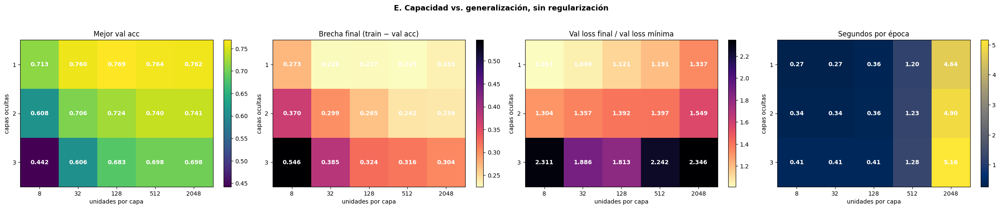

Configuración más sobreajustada (mayor subida de la val loss): 3x2048


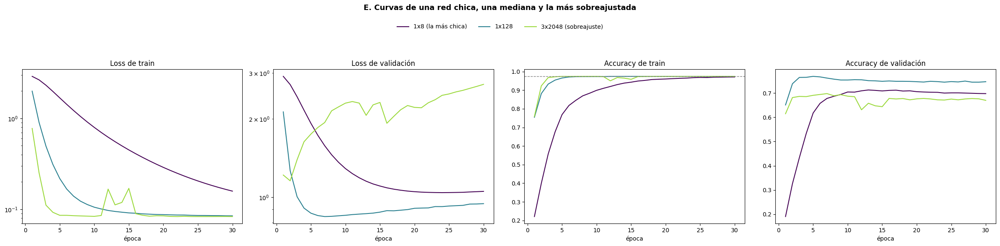

In [ ]:
OF_BASE = {**{k: BEST_CFG[k] for k in PREPRO_KEYS}, "batch_size": 64, "activation": "relu", "dropout": 0.0,
           "weight_decay": 0.0, "optimizer": "adam", "lr": 1e-3, "beta1": 0.9, "beta2": 0.999}
OF_WIDTHS = [8, 64] if MODO_RAPIDO else [8, 32, 128, 512, 2048]
OF_DEPTHS = [1, 2, 3]
run_group("overfit", {f"{L}x{w}": {**OF_BASE, "hidden": [w] * L} for L in OF_DEPTHS for w in OF_WIDTHS})

rows = []
for name, h in dyn["overfit"].items():
    L, w = map(int, name.split("x"))
    vl = np.array(h["val_loss"])
    rows.append({"capas": L, "unidades": w, "params": h["n_params"], "train acc final": h["train_acc"][-1],
                 "val acc final": h["val_acc"][-1], "mejor val acc": h["best_val_acc"], "época mejor": h["best_epoch"],
                 "brecha final": h["train_acc"][-1] - h["val_acc"][-1], "train loss final": h["train_loss"][-1],
                 "val loss mín": np.nanmin(vl), "época val loss mín": int(np.nanargmin(vl)) + 1,
                 "val loss final": vl[-1], "val loss final / mín": vl[-1] / np.nanmin(vl),
                 "s/época": np.mean(h["epoch_time"])})
df_of = pd.DataFrame(rows)
display(df_of.style.format({"params": "{:,.0f}", "train acc final": "{:.3f}", "val acc final": "{:.3f}",
                            "mejor val acc": "{:.3f}", "brecha final": "{:.3f}", "train loss final": "{:.2e}",
                            "val loss mín": "{:.3f}", "val loss final": "{:.3f}", "val loss final / mín": "{:.2f}",
                            "s/época": "{:.2f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 4, figsize=(24, 4.8))
for ax, (col, title, cmap) in zip(axes, [("mejor val acc", "Mejor val acc", "viridis"),
                                        ("brecha final", "Brecha final (train − val acc)", "magma_r"),
                                        ("val loss final / mín", "Val loss final / val loss mínima", "magma_r"),
                                        ("s/época", "Segundos por época", "cividis")]):
    M = df_of.pivot(index="capas", columns="unidades", values=col).loc[OF_DEPTHS, OF_WIDTHS]
    im = ax.imshow(M.values, cmap=cmap, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.values[i, j]:.3f}" if col != "s/época" else f"{M.values[i, j]:.2f}",
                    ha="center", va="center", color="w", fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(OF_WIDTHS)))
    ax.set_xticklabels(OF_WIDTHS)
    ax.set_yticks(range(len(OF_DEPTHS)))
    ax.set_yticklabels(OF_DEPTHS)
    ax.set_xlabel("unidades por capa")
    ax.set_ylabel("capas ocultas")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle("E. Capacidad vs. generalización, sin regularización", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# La configuración más sobreajustada: la de mayor subida relativa de la val loss
OVERFIT_NAME = df_of.sort_values("val loss final / mín").iloc[-1]
OVERFIT_NAME = f"{int(OVERFIT_NAME['capas'])}x{int(OVERFIT_NAME['unidades'])}"
SMALL_NAME, MID_NAME = f"1x{OF_WIDTHS[0]}", f"1x{OF_WIDTHS[len(OF_WIDTHS) // 2]}"
print(f"Configuración más sobreajustada (mayor subida de la val loss): {OVERFIT_NAME}")
dyn["overfit_sel"] = {f"{SMALL_NAME} (la más chica)": dyn["overfit"][SMALL_NAME], MID_NAME: dyn["overfit"][MID_NAME],
                      f"{OVERFIT_NAME} (sobreajuste)": dyn["overfit"][OVERFIT_NAME]}
plot_group("overfit_sel", "E. Curvas de una red chica, una mediana y la más sobreajustada", ordered=True)

### Análisis E: sobreajuste

La grilla usa una configuración común para todas las redes: Adam con $\eta=10^{-3}$, ReLU, batch 64, sin dropout ni weight decay, y el preprocesamiento de la referencia (40.000 términos). Las 15 redes llegan al techo de train (0.971 a 0.974; el máximo posible es 0.9743, sección 5.0), así que todas tienen capacidad para memorizar todo lo que se puede memorizar. Lo que las distingue es cuánto generalizan:

| | 8 | 32 | 128 | 512 | 2048 |
|---|---|---|---|---|---|
| **Mejor val acc, 1 capa** | 0.713 | 0.760 | 0.769 | 0.764 | 0.762 |
| **Mejor val acc, 2 capas** | 0.608 | 0.706 | 0.724 | 0.740 | 0.741 |
| **Mejor val acc, 3 capas** | 0.442 | 0.606 | 0.683 | 0.698 | 0.698 |
| **Val loss final / mínima, 1 capa** | 1.01 | 1.05 | 1.12 | 1.19 | 1.34 |
| **Val loss final / mínima, 2 capas** | 1.30 | 1.36 | 1.39 | 1.40 | 1.55 |
| **Val loss final / mínima, 3 capas** | 2.31 | 1.89 | 1.81 | 2.24 | 2.35 |

**Configuración sobreajustada: 3 capas ocultas de 2048 unidades** (90.355.732 parámetros, 113 veces los de la regresión softmax, para 9.051 documentos de train). Es la de mayor subida relativa de la loss de validación, y su comportamiento es el típico de un modelo sobreajustado:

- llega al techo de train en pocas épocas y la loss de train baja a 0.08, el piso que imponen los documentos inseparables;
- la loss de validación es mínima en la **época 2** (1.157) y desde ahí sube hasta **2.714** en la época 30;
- la accuracy de validación nunca pasa de 0.698 y termina en 0.670, con una brecha de 0.30 respecto de train. La red de 1 × 128, con la misma configuración, llega a 0.769.

**El sobreajuste depende más de la profundidad que de la cantidad de parámetros.** Con una capa, incluso 2048 unidades (82 millones de parámetros) llegan a 0.762 y su loss de validación sube un 34 %. Con tres capas, todas las redes sobreajustan fuerte, incluida la 3 × 8, que tiene 320.332 parámetros, menos de la mitad que la regresión softmax. Esa red tiene la mayor brecha de la grilla: 0.972 en train contra 0.426 en validación. Su primera capa proyecta los 40.000 términos a 8 dimensiones, y las dos capas siguientes recortan ese espacio en regiones muy irregulares que separan documentos individuales de train; aprende particiones arbitrarias, no temas. En las redes de 3 capas, ensanchar **mejora** la validación (0.442 → 0.698), porque una primera capa más ancha conserva más información de las palabras antes de que las capas siguientes la deformen.

**La red más chica (1 × 8)** es el otro extremo: su loss de validación no sube (cociente 1.01) y se estabiliza en 0.713. Tiene poca capacidad y no sobreajusta, pero tampoco alcanza a las redes de 32 a 2048 unidades.

En tiempo, las redes de 2048 unidades tardan entre 4.6 y 5.2 s por época, contra 0.27 a 0.41 s de las de hasta 128 unidades.

[reg] 3x2048 sin regularización          misma corrida que en un grupo anterior: se reutiliza
[reg] dropout 0.5                        mejor val acc 0.7061 (ép.  7) | final: val acc 0.6955, train acc 0.974, val loss 2.403 (mín 1.079 ép. 2) | 90,355,732 params | 5.17 s/época
[reg] weight decay 1e-5                  mejor val acc 0.6770 (ép.  3) | final: val acc 0.6677, train acc 0.973, val loss 1.831 (mín 1.205 ép. 2) | 90,355,732 params | 5.98 s/época
[reg] dropout 0.5 + weight decay 1e-5    mejor val acc 0.6880 (ép.  4) | final: val acc 0.6699, train acc 0.972, val loss 2.141 (mín 1.103 ép. 2) | 90,355,732 params | 5.99 s/época
[reg] capacidad de la referencia de Optuna mejor val acc 0.7676 (ép.  3) | final: val acc 0.7468, train acc 0.974, val loss 1.032 (mín 0.833 ép. 3) | 40,981,524 params | 2.34 s/época


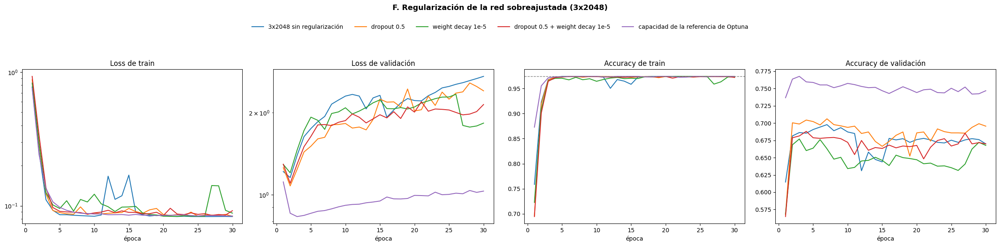

In [ ]:
# F. Regularización de la configuración sobreajustada
OF_L, OF_W = map(int, OVERFIT_NAME.split("x"))
OF_CFG = {**OF_BASE, "hidden": [OF_W] * OF_L}
run_group("reg", {
    f"{OVERFIT_NAME} sin regularización":       OF_CFG,
    "dropout 0.5":                             {**OF_CFG, "dropout": 0.5},
    "weight decay 1e-5":                        {**OF_CFG, "weight_decay": 1e-5},
    "dropout 0.5 + weight decay 1e-5":          {**OF_CFG, "dropout": 0.5, "weight_decay": 1e-5},
    "capacidad de la referencia de Optuna":     {**OF_CFG, "hidden": BEST_CFG["hidden"], "dropout": BEST_CFG["dropout"],
                                                 "weight_decay": BEST_CFG["weight_decay"]},
})
plot_group("reg", f"F. Regularización de la red sobreajustada ({OVERFIT_NAME})")

### Análisis F: regularización

| Red 3 × 2048 | Mejor val acc | Época | Val acc final | Val loss mín → final | s/época |
|---|---|---|---|---|---|
| sin regularización | 0.6977 | 7 | 0.6699 | 1.157 → 2.714 | 5.16 |
| dropout 0.5 | 0.7061 | 7 | 0.6955 | 1.079 → 2.403 | 5.17 |
| weight decay $10^{-5}$ | 0.6770 | 3 | 0.6677 | 1.205 → 1.831 | 5.98 |
| dropout 0.5 + weight decay $10^{-5}$ | 0.6880 | 4 | 0.6699 | 1.103 → 2.141 | 5.99 |
| capacidad de la referencia (1 × 1024, dropout 0.08) | **0.7676** | 3 | **0.7468** | 0.833 → 1.032 | 2.34 |

Regularizar la red sobreajustada ayuda poco:

- El **dropout 0.5** es lo que más sirve: sube el máximo 0.8 puntos y la accuracy final 2.6, pero la loss de validación igual se duplica desde su mínimo.
- El **weight decay** de $10^{-5}$ frena la subida de la loss de validación (termina en 1.83 en lugar de 2.71), pero no mejora la accuracy. Con Adam, la penalización L2 se suma al gradiente y después se divide por $\sqrt{\hat v}$ como el resto, así que su efecto depende de la escala del gradiente de cada peso.
- La **combinación** no supera al dropout solo.

Ninguna de las tres se acerca a **usar la capacidad adecuada**. Con la arquitectura de la referencia (una capa de 1024) y el resto de la configuración igual, el máximo sube a 0.7676 y la accuracy final a 0.7468, con una loss de validación que sube mucho menos (0.833 → 1.032), y cada época tarda menos de la mitad. Para este problema, la regularización más efectiva es elegir bien la arquitectura y cortar con early stopping. Dropout y weight decay son ajustes finos sobre una arquitectura razonable, no una forma de rescatar una red demasiado profunda.

## 6. Performance y tiempos a lo ancho de todos los entrenamientos

Se juntan en una sola tabla los trials de Optuna y las corridas de la sección 5 (cada corrida una sola vez). Para cada una: cantidad de parámetros, segundos por época, épocas, tiempo total de entrenamiento y mejor accuracy de validación. Los gráficos muestran:

1. **Segundos por época vs. parámetros** (escala log-log), coloreado por tamaño de batch: cuánto cuesta la capacidad.
2. **Mejor val acc vs. tiempo total de entrenamiento**: qué entrenamientos dan la mejor relación resultado/tiempo.
3. **Mejor val acc vs. parámetros**: si más capacidad mejora la validación.
4. **Distribución de la val acc por optimizador y por activación** sobre todos los entrenamientos.

Los tiempos absolutos dependen del hardware donde se ejecuta la notebook; las tendencias no.

484 entrenamientos en total | tiempo de entrenamiento acumulado: 77.3 min


n  params_mediana  s_por_época_mediana  seg_total  mejor_val_acc_max
origen               estado                                                                          
búsqueda principal   completo   45      20490772.0                0.714    257.200              0.769
                     podado     75      10258004.0                0.358    169.335                NaN
búsqueda sin pruning completo  120      10245396.0                0.349    664.529              0.775
optimizador adam     completo   12      40981524.0                0.863    112.255              0.773
                     podado     13      40981524.0                0.859     33.489                NaN
optimizador rmsprop  completo   11      40981524.0                0.862     87.104              0.770
                     podado     14      40981524.0                0.858     56.733                NaN
optimizador sgd      completo   22      40981524.0                0.603    250.167              0.737
                     podado      3      40981524.0                0.599      6.215                NaN
profundidad 0        completo   23        800020.0                0.201     59.966              0.757
                     podado      7        800020.0                0.198      3.489                NaN
profundidad 1        completo   20      40981524.0                0.862    215.473              0.771
                     podado     10      30736148.0                0.718     17.847                NaN
profundidad 2        completo   17      20616980.0                0.755    144.363              0.755
                     podado     13      20616980.0                0.759     39.726                NaN
profundidad 3        completo   25      10589716.0                0.974    442.251              0.722
                     podado      5      10278484.0                1.159     33.778                NaN
sección 5 (act)      completo    6      40981524.0                0.861    154.994              0.771
sección 5 (adam)     completo    4      40981524.0                0.861    103.177              0.773
sección 5 (depth)    completo    4      30867476.0                0.675    175.670              0.771
sección 5 (opt_cmp)  completo    3      40981524.0                0.861     72.927              0.773
sección 5 (overfit)  completo   15       5139220.0                0.409    647.366              0.769
sección 5 (reg)      completo    4      90355732.0                5.574    584.276              0.768
sección 5 (rmsprop)  completo    5      40981524.0                0.860    125.191              0.770
sección 5 (sgd)      completo    4      40981524.0                0.601     71.180              0.735
sección 5 (width)    completo    4       6403380.0                0.156    112.134              0.769

mejor val acc              s/época             
                 median    max count  median    max count
optimizer                                                
adam              0.755  0.775   270   0.602  5.989   382
rmsprop           0.755  0.770    30   0.859  2.330    48
sgd               0.476  0.737    44   0.601  0.714    54

mejor val acc              s/época             
                  median    max count  median    max count
activation                                                
elu                0.753  0.773   148   0.699  4.265   203
gelu               0.763  0.771    29   0.768  4.332    55
leaky_relu         0.755  0.775    43   0.427  2.341    52
ninguna            0.754  0.757    24   0.200  0.407    31
relu               0.750  0.775    48   0.365  5.989    55
sigmoid            0.695  0.768     9   0.425  4.264    20
tanh               0.737  0.769    43   0.732  4.328    68

mejor val acc              s/época             
             median    max count  median    max count
capas                                                
0             0.754  0.757    24   0.200  0.407    31
1             0.762  0.775   232   0.612  4.639   333
2             0.732  0.763    46   0.618  4.899    71
3             0.690  0.726    42   0.656  5.989    49

s/época              
            median    min    max
batch_size                      
32           1.321  0.393  4.342
64           0.603  0.197  5.989
128          0.350  0.098  1.464
256          0.686  0.055  3.351

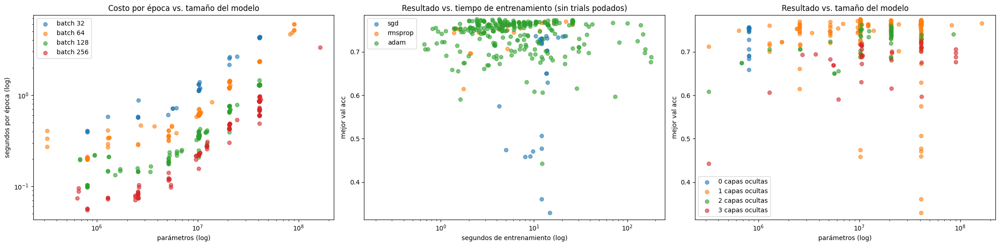

In [ ]:
STUDIES = {"búsqueda principal": study, "búsqueda sin pruning": study_np,
           **{f"profundidad {L}": st for L, st in depth_studies.items()},
           **{f"optimizador {o}": st for o, st in opt_studies.items()}}


def row(origen, estado, c, n_params, epochs, s_per_epoch, t_train, best):
    return {"origen": origen, "estado": estado, "optimizer": c["optimizer"],
            "activation": c["activation"] if c["hidden"] else "ninguna", "batch_size": c["batch_size"],
            "capas": len(c["hidden"]), "params": n_params, "épocas": epochs, "s/época": s_per_epoch,
            "seg entrenando": t_train, "mejor val acc": best}


all_rows = []
for label, st in STUDIES.items():
    for t in st.trials:
        if t.state not in FINISHED:
            continue
        ua = t.user_attrs
        pr = t.state == optuna.trial.TrialState.PRUNED
        all_rows.append(row(label, "podado" if pr else "completo", ua["cfg"], ua["n_params"], ua["epochs_run"],
                            ua["s_per_epoch"], ua["t_train"], np.nan if pr else t.value))
seen = set()
for g, runs in dyn.items():
    for name, h in runs.items():
        if id(h) in seen:
            continue
        seen.add(id(h))
        all_rows.append(row(f"sección 5 ({g})", "completo", h["cfg"], h["n_params"], h["epochs_run"],
                            np.mean(h["epoch_time"]), h["train_time"], h["best_val_acc"]))
df_all = pd.DataFrame(all_rows)
print(f"{len(df_all)} entrenamientos en total | tiempo de entrenamiento acumulado: {df_all['seg entrenando'].sum() / 60:.1f} min")
display(df_all.groupby(["origen", "estado"]).agg(n=("params", "count"), params_mediana=("params", "median"),
                                                 s_por_época_mediana=("s/época", "median"), seg_total=("seg entrenando", "sum"),
                                                 mejor_val_acc_max=("mejor val acc", "max")).round(3))
display(df_all.groupby("optimizer")[["mejor val acc", "s/época"]].agg(["median", "max", "count"]).round(3))
display(df_all.groupby("activation")[["mejor val acc", "s/época"]].agg(["median", "max", "count"]).round(3))
display(df_all.groupby("capas")[["mejor val acc", "s/época"]].agg(["median", "max", "count"]).round(3))
display(df_all.groupby("batch_size")[["s/época"]].agg(["median", "min", "max"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
ax = axes[0]
for i, bs in enumerate(sorted(df_all.batch_size.unique())):
    s = df_all[df_all.batch_size == bs]
    ax.scatter(s["params"], s["s/época"], alpha=0.6, label=f"batch {bs}", color=f"C{i}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("parámetros (log)")
ax.set_ylabel("segundos por época (log)")
ax.set_title("Costo por época vs. tamaño del modelo")
ax.legend()

ok = df_all["mejor val acc"].notna()
lo = max(0.3, df_all.loc[ok, "mejor val acc"].quantile(0.05) - 0.02)
hi = df_all["mejor val acc"].max() + 0.01
ax = axes[1]
for opt_name, c in OPT_COLORS.items():
    s = df_all[(df_all.optimizer == opt_name) & ok]
    ax.scatter(s["seg entrenando"], s["mejor val acc"], alpha=0.6, color=c, label=opt_name)
ax.set_xscale("log")
ax.set_xlabel("segundos de entrenamiento (log)")
ax.set_ylabel("mejor val acc")
ax.set_title("Resultado vs. tiempo de entrenamiento (sin trials podados)")
ax.set_ylim(lo, hi)
ax.legend()

ax = axes[2]
for L in [0, 1, 2, 3]:
    s = df_all[(df_all["capas"] == L) & ok]
    if len(s):
        ax.scatter(s["params"], s["mejor val acc"], alpha=0.6, label=f"{L} capas ocultas")
ax.set_xscale("log")
ax.set_xlabel("parámetros (log)")
ax.set_ylabel("mejor val acc")
ax.set_title("Resultado vs. tamaño del modelo")
ax.set_ylim(lo, hi)
ax.legend()
plt.tight_layout()
plt.show()

### Análisis de performance y tiempos

En total se entrenaron **484 modelos**, con 77.3 minutos de entrenamiento acumulado en la GPU: 240 trials de las búsquedas con y sin pruning, 195 de las búsquedas por profundidad y por optimizador, y 49 corridas de la sección 5.

**Performance.**

- **El rango de los mejores resultados es angosto.** El mejor de cada búsqueda queda entre 0.755 y 0.775, salvo la de 3 capas (0.722) y la de SGD (0.737). Una regresión softmax bien ajustada llega a 0.757, y el mejor MLP a 0.775 (el mejor trial de la búsqueda sin pruning). Casi todo lo que se puede ganar ya está en la representación TF-IDF; la capa oculta agrega entre 1.5 y 2 puntos.
- **Por cantidad de capas:** sobre todos los entrenamientos, la mediana de la mejor accuracy de validación es 0.754 sin capas ocultas, 0.762 con 1 capa, 0.732 con 2 y 0.690 con 3. Los máximos respectivos son 0.757, 0.775, 0.763 y 0.726.
- **Por optimizador:** Adam y RMSProp tienen la misma mediana (0.755) y SGD una mucho menor (0.476, por sus divergencias).
- **Por activación:** GELU (0.763), Leaky ReLU (0.755), ELU (0.753) y ReLU (0.750) quedan cerca, tanh algo más abajo (0.737, porque es la elegida por las búsquedas de 2 y 3 capas) y la sigmoide última (0.695).
- **Resultado vs. tamaño** (gráfico de la derecha): las redes de 1 capa forman una franja plana entre 0.75 y 0.775 desde 640 mil hasta 164 millones de parámetros. Más parámetros no compran accuracy.

**Tiempos.**

- **El tiempo por época crece con el tamaño y baja con el batch** (gráfico de la izquierda). Para un mismo tamaño de red, cada duplicación del batch reduce el tiempo por época, porque se hacen la mitad de pasos y cada paso tiene un costo fijo: lanzar los kernels de la GPU y el paso del optimizador. Ese costo fijo domina con redes chicas: con batch 32, una red de un millón de parámetros tarda ~0.4 s por época, y con batch 256 tarda menos de 0.1 s. Con más de ~10 millones de parámetros manda el cálculo, y el tiempo crece en proporción a los parámetros: la red de 164 millones tarda 3.35 s por época con batch 256, y las de 90 millones, entre 5 y 6 s con batch 64.
- **La activación no cambia el tiempo**, y SGD es un 15 a 20 % más barato por época que Adam o RMSProp porque no guarda estado por parámetro.

**Resultado vs. tiempo** (gráfico del centro). Los mejores resultados se obtienen con entrenamientos de 2 a 30 segundos. Los entrenamientos de 100 a 200 segundos son las redes enormes de las secciones 5 C, E y F, y ninguno supera a los cortos. Las secciones 5 E y F gastaron 1232 s de entrenamiento, más que la búsqueda principal completa (618 s), para mostrar redes que generalizan peor. Entre las búsquedas, la de 3 capas fue la más cara (507 s) y la de peor resultado, porque su mejor configuración usa batch 32.

## 7. Modelo final y comparación con la regresión softmax en test

**Modelo final.** Es la configuración con mejor accuracy de validación entre todas las búsquedas, salvo la búsqueda sin pruning de la sección 4.2, que se corrió como control para medir el efecto del pruning: es decir, la búsqueda principal y las búsquedas por profundidad y por optimizador de la sección 5. Se reentrena con **todo** el train (11.314 documentos, con el vectorizador ajustado de nuevo sobre todo el train) durante la cantidad de épocas en la que ese trial alcanzó su mejor validación. El early stopping se decide con validación, no con test.

Se comparan, todos entrenados con todo el train:

- **Regresión softmax ajustada**: el mejor trial de la búsqueda de 0 capas ocultas (sección 5 B), con el **mismo preprocesamiento** que el MLP y sus propios hiperparámetros. La diferencia con el MLP mide solo el efecto de las capas ocultas.
- **Regresión softmax del TP1**: stopwords removidas, stemming, unigramas, 10.000 términos, `min_df=1`, Adam $\eta=0.00857$, batch 64 y 6 épocas (la de mejor validación en el TP1). Sirve de referencia con el TP anterior. La diferencia con la softmax ajustada mide el efecto del cambio de preprocesamiento.
- **Red sobreajustada** de la sección 5 E, con todas sus épocas.

Las curvas por época sobre test se muestran solo como información: no se usan para elegir nada.

Modelo final: mejor trial de 'optimizador adam' (#5), val acc 0.7733 en la época 15
  {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 40000, 'min_df': 1, 'batch_size': 256, 'optimizer': 'adam', 'hidden': [1024], 'activation': 'elu', 'dropout': 0.07613861387437061, 'weight_decay': 0.0, 'lr': 0.00023270677083837802, 'beta1': 0.6490786990501735, 'beta2': 0.9524231675200606}
Softmax ajustada: val acc 0.7565 en la época 6
  {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 40000, 'min_df': 1, 'batch_size': 64, 'optimizer': 'adam', 'hidden': [], 'activation': 'relu', 'dropout': 0.0, 'weight_decay': 0.0, 'lr': 0.008300655333928134, 'beta1': 0.8689639141307516, 'beta2': 0.9794938845143862}
Softmax (TP1)                épocas  6 | vocabulario  10000 |     200,020 params | train acc 0.943 | test acc 0.6751 | F1 macro 0.6622 | test loss 1.208 | 1.5 s | predicción para x = 0: rec.sport.baseball
Softmax 

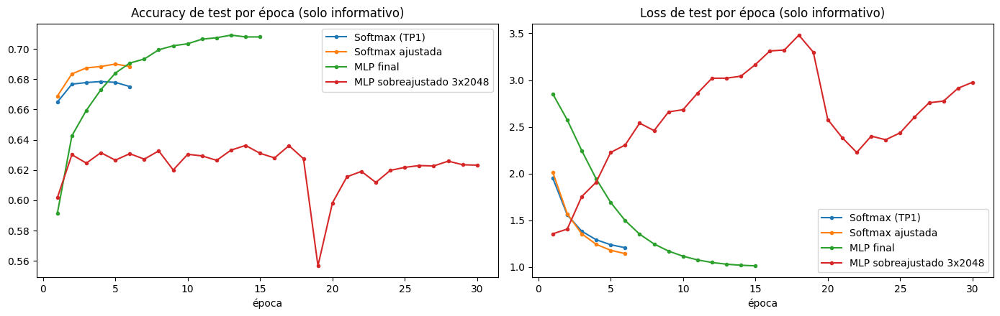

In [ ]:
CANDIDATES = {k: v for k, v in STUDIES.items() if k != "búsqueda sin pruning"}
final_label, final_trial = max(((k, st.best_trial) for k, st in CANDIDATES.items()), key=lambda x: x[1].value)
FINAL_CFG = final_trial.user_attrs["cfg"]
FINAL_EPOCHS = int(final_trial.user_attrs["best_epoch"])
SOFT_TRIAL = depth_studies[0].best_trial
print(f"Modelo final: mejor trial de '{final_label}' (#{final_trial.number}), val acc {final_trial.value:.4f} en la época "
      f"{FINAL_EPOCHS}\n  {FINAL_CFG}")
print(f"Softmax ajustada: val acc {SOFT_TRIAL.value:.4f} en la época {SOFT_TRIAL.user_attrs['best_epoch']}\n  "
      f"{SOFT_TRIAL.user_attrs['cfg']}")

TP1_CFG = {"remove_stopwords": True, "normalization": "stem", "ngram_range": "1gram", "max_features": 10000, "min_df": 1,
           "batch_size": 64, "hidden": [], "activation": "relu", "dropout": 0.0, "weight_decay": 0.0,
           "optimizer": "adam", "lr": 0.008573297139133254}
y_train_t = torch.tensor(y_train_all, dtype=torch.long, device=device)
y_test_t = torch.tensor(y_test_all, dtype=torch.long, device=device)
_full_cache = {}


def full_data(cfg):
    key = tuple(cfg[k] for k in PREPRO_KEYS)
    if key not in _full_cache:
        tr, te = preprocessed_cache[(cfg["remove_stopwords"], cfg["normalization"])]
        _full_cache[key] = vectorize_data(tr, te, NGRAMS[cfg["ngram_range"]], cfg["max_features"], cfg["min_df"])
    return _full_cache[key]


MLP_NAME, SOFT_NAME = "MLP final", "Softmax ajustada"
finals = {}
for name, cfg, ep in [("Softmax (TP1)", TP1_CFG, 6),
                      (SOFT_NAME, SOFT_TRIAL.user_attrs["cfg"], int(SOFT_TRIAL.user_attrs["best_epoch"])),
                      (MLP_NAME, FINAL_CFG, FINAL_EPOCHS),
                      (f"MLP sobreajustado {OVERFIT_NAME}", OF_CFG, EPOCHS_DYN)]:
    _dense_last["key"], _dense_last["data"] = None, None
    if device.type == "cuda":
        torch.cuda.empty_cache()
    X_tr_s, X_te_s, vec = full_data(cfg)
    X_tr_f, X_te_f = to_device_dense(X_tr_s), to_device_dense(X_te_s)
    writer = SummaryWriter(f"runs/final/{''.join(ch if ch.isalnum() else '_' for ch in name)}")
    model_f, h = train_mlp(cfg, X_tr_f, y_train_t, X_te_f, y_test_t, epochs=ep, writer=writer)
    writer.close()
    with torch.no_grad():
        model_f.eval()
        preds = torch.cat([model_f(X_te_f[i:i + 4096]).argmax(1) for i in range(0, len(X_te_f), 4096)]).cpu().numpy()
        pred_zero = model_f(torch.zeros(1, X_te_f.shape[1], device=device)).argmax(1).item()
    finals[name] = {"model": model_f, "preds": preds, "h": h, "vec": vec, "X_tr": X_tr_s, "X_te": X_te_s, "pred_zero": pred_zero}
    with mlflow.start_run(run_name=f"final_{name}"):
        mlflow.log_params({k: str(v) for k, v in cfg.items()} | {"epochs": ep})
        mlflow.log_metrics({"test_acc": accuracy_score(y_test_all, preds),
                            "test_f1_macro": f1_score(y_test_all, preds, average="macro")})
    print(f"{name:28s} épocas {ep:2d} | vocabulario {X_tr_s.shape[1]:>6} | {h['n_params']:>11,} params | "
          f"train acc {h['train_acc'][-1]:.3f} | test acc {accuracy_score(y_test_all, preds):.4f} | "
          f"F1 macro {f1_score(y_test_all, preds, average='macro'):.4f} | test loss {h['val_loss'][-1]:.3f} | "
          f"{h['train_time']:.1f} s | predicción para x = 0: {class_names[pred_zero]}")
    del X_tr_f, X_te_f

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, f in finals.items():
    axes[0].plot(range(1, len(f["h"]["val_acc"]) + 1), f["h"]["val_acc"], marker="o", ms=3, label=name)
    axes[1].plot(range(1, len(f["h"]["val_loss"]) + 1), f["h"]["val_loss"], marker="o", ms=3, label=name)
axes[0].set_title("Accuracy de test por época (solo informativo)")
axes[1].set_title("Loss de test por época (solo informativo)")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()

Train completo: 11314 documentos | con vector nulo: 323 (2.9%) | accuracy máxima alcanzable: 0.9733
Clases más frecuentes entre los documentos vacíos del train completo: {'rec.autos': 32, 'rec.sport.baseball': 25, 'comp.os.ms-windows.misc': 25}
Predicción para un documento vacío (x = 0): MLP -> rec.autos | softmax ajustada -> rec.sport.baseball

                          precision    recall  f1-score   support

             alt.atheism      0.530     0.520     0.525       319
           comp.graphics      0.652     0.704     0.677       389
 comp.os.ms-windows.misc      0.650     0.617     0.633       394
comp.sys.ibm.pc.hardware      0.650     0.645     0.648       392
   comp.sys.mac.hardware      0.753     0.704     0.728       385
          comp.windows.x      0.801     0.704     0.749       395
            misc.forsale      0.780     0.774     0.777       390
               rec.autos      0.509     0.790     0.619       396
         rec.motorcycles      0.774     0.766     0.770  

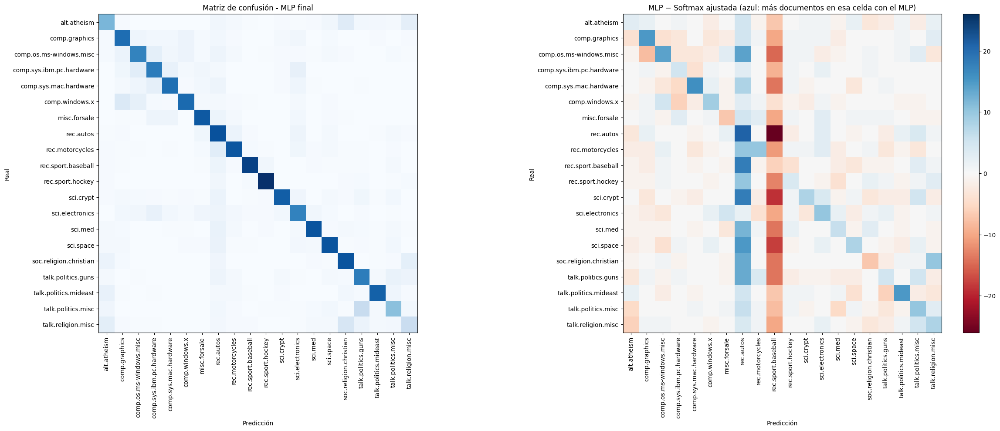

,F1 softmax ajustada,F1 MLP,diferencia
rec.autos,0.711,0.619,-0.092
misc.forsale,0.789,0.777,-0.012
soc.religion.christian,0.735,0.726,-0.010
rec.sport.hockey,0.902,0.905,0.003
sci.electronics,0.617,0.621,0.003
talk.politics.misc,0.515,0.523,0.008
rec.motorcycles,0.758,0.770,0.012
sci.crypt,0.776,0.792,0.016
comp.windows.x,0.732,0.749,0.017
comp.sys.ibm.pc.hardware,0.629,0.648,0.019


Top 10 confusiones del MLP (real -> predicha): cantidad, % de la clase real y cantidad con la softmax ajustada
  talk.politics.misc         -> talk.politics.guns           85 (27.4%) | softmax: 88
  talk.religion.misc         -> soc.religion.christian       57 (22.7%) | softmax: 60
  comp.windows.x             -> comp.graphics                49 (12.4%) | softmax: 48
  alt.atheism                -> soc.religion.christian       42 (13.2%) | softmax: 45
  comp.sys.ibm.pc.hardware   -> comp.os.ms-windows.misc      38 (9.7%) | softmax: 39
  rec.motorcycles            -> rec.autos                    38 (9.5%) | softmax: 28
  talk.religion.misc         -> alt.atheism                  36 (14.3%) | softmax: 42
  alt.atheism                -> talk.religion.misc           34 (10.7%) | softmax: 32
  comp.os.ms-windows.misc    -> comp.sys.ibm.pc.hardware     33 (8.4%) | softmax: 36
  soc.religion.christian     -> talk.religion.misc           33 (8.3%) | softmax: 23

Docs de test con vector TF-IDF n

In [ ]:
best_name = MLP_NAME
p_mlp, p_soft = finals[MLP_NAME]["preds"], finals[SOFT_NAME]["preds"]

# Documentos vacíos y accuracy máxima alcanzable en el train completo, con el preprocesamiento del modelo final
empty_full, _, max_acc_full = separability(finals[MLP_NAME]["X_tr"], y_train_all)
print(f"Train completo: {len(y_train_all)} documentos | con vector nulo: {empty_full.sum()} ({empty_full.mean():.1%}) | "
      f"accuracy máxima alcanzable: {max_acc_full:.4f}")
print("Clases más frecuentes entre los documentos vacíos del train completo:",
      {class_names[k]: v for k, v in Counter(y_train_all[empty_full]).most_common(3)})
print(f"Predicción para un documento vacío (x = 0): MLP -> {class_names[finals[MLP_NAME]['pred_zero']]} | "
      f"softmax ajustada -> {class_names[finals[SOFT_NAME]['pred_zero']]}\n")
print(classification_report(y_test_all, p_mlp, labels=range(NUM_CLASSES), target_names=class_names, digits=3))

cm = confusion_matrix(y_test_all, p_mlp, labels=range(NUM_CLASSES))
cm_soft = confusion_matrix(y_test_all, p_soft, labels=range(NUM_CLASSES))
fig, axes = plt.subplots(1, 2, figsize=(24, 10))
axes[0].imshow(cm, cmap="Blues")
axes[0].set_title(f"Matriz de confusión - {best_name}")
diff = cm - cm_soft
lim = np.abs(diff).max()
im = axes[1].imshow(diff, cmap="RdBu", vmin=-lim, vmax=lim)
axes[1].set_title("MLP − Softmax ajustada (azul: más documentos en esa celda con el MLP)")
plt.colorbar(im, ax=axes[1], fraction=0.046)
for ax in axes:
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels(class_names, rotation=90)
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

f1_mlp = f1_score(y_test_all, p_mlp, average=None, labels=range(NUM_CLASSES))
f1_soft = f1_score(y_test_all, p_soft, average=None, labels=range(NUM_CLASSES))
df_f1 = pd.DataFrame({"F1 softmax ajustada": f1_soft, "F1 MLP": f1_mlp, "diferencia": f1_mlp - f1_soft}, index=class_names)
display(df_f1.sort_values("diferencia").style.format("{:.3f}"))

cm_norm = cm / cm.sum(axis=1, keepdims=True)
off = sorted(((cm[i, j], cm_norm[i, j], class_names[i], class_names[j], cm_soft[i, j])
              for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j), reverse=True)
print("Top 10 confusiones del MLP (real -> predicha): cantidad, % de la clase real y cantidad con la softmax ajustada")
for n, frac, a, b, ns in off[:10]:
    print(f"  {a:26s} -> {b:26s} {int(n):4d} ({frac:.1%}) | softmax: {int(ns)}")

empty = np.asarray(finals[best_name]["X_te"].sum(axis=1)).ravel() == 0
print(f"\nDocs de test con vector TF-IDF nulo: {empty.sum()} ({empty.mean():.1%}); "
      f"todos reciben la misma predicción: '{class_names[np.bincount(p_mlp[empty]).argmax()]}' "
      f"(accuracy sobre ellos {(p_mlp[empty] == y_test_all[empty]).mean():.3f})")
agree = (p_mlp == p_soft).mean()
print(f"MLP y softmax ajustada predicen lo mismo en el {agree:.1%} de los documentos de test; "
      f"solo acierta el MLP: {((p_mlp == y_test_all) & (p_soft != y_test_all)).sum()} | "
      f"solo acierta la softmax: {((p_soft == y_test_all) & (p_mlp != y_test_all)).sum()}")

### Análisis de la evaluación final

El modelo final es el mejor trial de la búsqueda de Adam (sección 5 D): una capa de 1024 unidades con ELU, dropout 0.08, Adam ($\eta=2.3\cdot10^{-4}$, $\beta_1=0.649$, $\beta_2=0.952$), batch 256 y 15 épocas, con 0.7733 de validación. La selección considera todas las búsquedas menos la búsqueda sin pruning, que funciona como control del pruning. Esa búsqueda tuvo un trial con 0.7751, pero la diferencia con el elegido (0.2 puntos) es mucho menor que el error estándar, así que los dos son equivalentes. Todos los modelos se reentrenaron con los 11.314 documentos de train.

| Modelo | Vocabulario | Parámetros | Épocas | Accuracy test | F1 macro | Loss test | Tiempo |
|---|---|---|---|---|---|---|---|
| Regresión softmax del TP1 | 10.000 | 200.020 | 6 | 0.6751 | 0.6622 | 1.208 | 1.5 s |
| Regresión softmax ajustada (mismo preprocesamiento que el MLP) | 40.000 | 800.020 | 6 | 0.6884 | 0.6772 | 1.145 | 1.4 s |
| **MLP final** (1 × 1024, ELU) | 40.000 | 40.981.524 | 15 | **0.7079** | **0.6986** | **1.014** | 16.1 s |
| MLP sobreajustado (3 × 2048) | 40.000 | 90.355.732 | 30 | 0.6232 | 0.6189 | 2.977 | 192.5 s |

**Separación de efectos.**

- **Preprocesamiento:** de la softmax del TP1 a la softmax ajustada, el cambio de preprocesamiento (40.000 términos lematizados en lugar de 10.000 con stemming) y el reajuste de sus hiperparámetros aportan **+1.3 puntos**.
- **Capa oculta:** de la softmax ajustada al MLP, con el mismo preprocesamiento, aporta **+2.0 puntos** de accuracy y +2.1 de F1 macro, con menor loss. En validación la diferencia era parecida: 0.7733 contra 0.7565, +1.7.
- Los dos modelos predicen lo mismo en el 85.3 % de los documentos. Entre los que difieren, solo el MLP acierta en 363 y solo la softmax en 216: una ganancia neta de 147 documentos, el 2.0 % del test.

**La red sobreajustada** es la peor de las cuatro: 6.5 puntos por debajo de la softmax ajustada, con 113 veces más parámetros y 140 veces más tiempo de entrenamiento. Confirma en test lo visto en la sección 5 E.

**Validación vs. test.** El MLP pasa de 0.773 en validación a 0.708 en test (−6.5 puntos) y la softmax ajustada de 0.757 a 0.688 (−6.8). La caída es parecida en los dos modelos y tiene las mismas causas que se analizaron en el TP1: el test tiene mensajes posteriores a los de train, y la validación es una parte al azar del train, con los mismos hilos y autores.

**Por clase.** El MLP mejora el F1 en 17 de las 20 clases. Las mayores mejoras son `rec.sport.baseball` (+0.195), `comp.sys.mac.hardware` (+0.044) y `comp.graphics` (+0.035). Empeora en `rec.autos` (−0.092), `misc.forsale` (−0.012) y `soc.religion.christian` (−0.010); estas dos últimas diferencias son muy chicas.

Las variaciones grandes en baseball y en autos se explican sobre todo por los **documentos vacíos**. El train completo tiene 323 documentos con vector nulo (2.9 %), y entre ellos la clase más frecuente es `rec.autos` (32), seguida por `rec.sport.baseball` y `comp.os.ms-windows.misc`, con 25 cada una. Con $x=0$, la salida de la softmax es su sesgo $b$, y la del MLP es $W_2 f(b_1)+b_2$. En los dos casos no depende del documento, así que todos los vacíos reciben la misma predicción. Pero esos parámetros se aprenden con el gradiente de **todos** los documentos de train, no solo de los vacíos. Por eso la predicción para un vector nulo no tiene por qué ser la clase mayoritaria entre los vacíos: el MLP predice `rec.autos`, que sí lo es, y la softmax ajustada predice `rec.sport.baseball`, que con 25 documentos comparte el segundo lugar con `comp.os.ms-windows.misc`. En test hay 239 documentos vacíos (3.2 %), y el MLP acierta solo el 10.9 % de ellos. Esos ~240 documentos van a `rec.autos` en un modelo y a `rec.sport.baseball` en el otro: por eso `rec.autos` tiene recall alto (0.790) y precisión baja (0.509) con el MLP, y por eso baseball mejora tanto al dejar de recibirlos.

**Confusiones.** Las principales son las mismas en los dos modelos y en el TP1, con cantidades casi iguales:

- `talk.politics.misc` → `talk.politics.guns`: 85 con el MLP, 88 con la softmax;
- `talk.religion.misc` → `soc.religion.christian`: 57 y 60;
- `comp.windows.x` → `comp.graphics`: 49 y 48;
- `alt.atheism` → `soc.religion.christian`: 42 y 45.

Crece `rec.motorcycles` → `rec.autos` (de 28 a 38), por la misma tendencia del MLP hacia `rec.autos`. La capa oculta mejora el resultado general porque combina palabras, pero no resuelve las confusiones entre grupos que hablan del mismo tema con el mismo vocabulario. Distinguir `talk.religion.misc` de `soc.religion.christian` depende de la postura del autor, algo que un vector de frecuencias de palabras no conserva.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

## 8. Conclusiones

- **Búsqueda de hiperparámetros.** Se buscaron conjuntamente el preprocesamiento, el batch size, la cantidad de capas (1 a 3), las unidades por capa, seis funciones de activación, dropout, weight decay y tres optimizadores (SGD, RMSProp y Adam) con sus momentos de orden 1 y 2. Después se hizo una búsqueda propia para cada profundidad y para cada optimizador. La mejor configuración es con **una capa oculta de 1024 unidades**, ELU, dropout bajo y Adam con learning rate bajo ($2.3\cdot10^{-4}$), sobre 40.000 unigramas lematizados. Llega a **0.7733** de validación, contra 0.7565 de una regresión softmax ajustada con el mismo preprocesamiento.

- **Arquitectura.** Con los hiperparámetros ajustados para cada profundidad, una capa oculta es la mejor opción (0.771). Dos capas quedan al nivel de la regresión softmax (0.755) y tres, por debajo (0.722). La grilla sin regularización lleva a la misma conclusión con otra metodología. El ancho no cambia el máximo a partir de 64 unidades (0.762 a 0.769), pero cuanto más ancha es la red, antes sobreajusta y más cuesta entrenarla. Con una capa oculta, ReLU, Leaky ReLU, ELU, GELU y tanh son equivalentes. La sigmoide aprende varias veces más lento, porque su derivada es como máximo 0.25.

- **Optimizadores y momentos.** Ajustados por separado, Adam (0.773) y RMSProp (0.770) empatan y SGD queda más de tres puntos abajo (0.737). La normalización por el momento de orden 2 es decisiva con TF-IDF, porque las palabras raras reciben gradientes esporádicos y de escala muy distinta. A paso efectivo constante, el momento de orden 1 es lo que le permite entrenar a SGD: amplifica las direcciones consistentes y amortigua las ruidosas, y sin él el mismo paso diverge. En RMSProp y en Adam casi no cambia el resultado. $\alpha$ y $\beta_2$ regulan cuán grandes son los pasos de los pesos que se actualizan poco, y por lo tanto la velocidad del entrenamiento.

- **Sobreajuste.** La red **3 × 2048 sin regularización** (90 millones de parámetros) queda claramente sobreajustada. Llega al techo de train, su loss de validación sube de 1.157 a 2.714 desde la época 2, su validación no pasa de 0.698, y en test obtiene 0.6232, peor que la regresión softmax. El barrido mostró que el sobreajuste depende más de la profundidad que de la cantidad de parámetros: una red 3 × 8 con 320 mil parámetros generaliza mucho peor que una 1 × 2048 con 82 millones. Dropout y weight decay apenas mejoran a la red sobreajustada. Lo efectivo es elegir la capacidad adecuada y cortar con early stopping.

- **Tiempos y pruning.** Los mejores modelos se entrenan en 2 a 30 segundos, y las redes más grandes tardan decenas de veces más por época sin mejorar. El tiempo por época depende del batch size cuando la red es chica y de la cantidad de parámetros cuando es grande. El pruning con `MedianPruner` recortó un 56 % de las épocas y un 23 % del tiempo de la búsqueda, sin una pérdida de calidad significativa, pero tampoco la mejoró (0.7689 con pruning, 0.7751 sin pruning, una diferencia menor que el error estándar). El ahorro es moderado porque cada trial ya es corto y tiene costos fijos que no se podan.

- **Evaluación final.** En test, el MLP alcanza **0.7079** de accuracy y 0.699 de F1 macro. Supera por 2.0 puntos a la regresión softmax con el mismo preprocesamiento y por 3.3 a la del TP1; de esos 3.3, 1.3 corresponden al cambio de preprocesamiento. Las confusiones principales (política, religión, hardware) siguen siendo las mismas. La capa oculta ayuda a combinar palabras, pero el límite está en la representación: TF-IDF pierde el orden y el contexto, y una red de una capa ya aprovecha casi todo lo que esa representación ofrece.

In [ ]:
# Resumen numérico de la corrida
print(f"Entorno: {device} {gpu} | torch {torch.__version__} | optuna {optuna.__version__}")
for label, st in STUDIES.items():
    s = search_summary(st)
    print(f"{label:22s}: {s['trials completos'] + s['trials podados']} trials ({s['trials podados']} podados), "
          f"{st.user_attrs['seconds']:.0f} s, mejor val acc {s['mejor val acc']:.4f}")
print(f"Modelo final: '{final_label}' #{final_trial.number}, val acc {final_trial.value:.4f} (época {FINAL_EPOCHS}) | {FINAL_CFG}")
for name, f in finals.items():
    print(f"Test {name:28s}: acc {accuracy_score(y_test_all, f['preds']):.4f} | "
          f"F1 macro {f1_score(y_test_all, f['preds'], average='macro'):.4f}")

Entorno: cuda Tesla T4 | torch 2.11.0+cu130 | optuna 5.0.0
búsqueda principal    : 120 trials (75 podados), 618 s, mejor val acc 0.7689
búsqueda sin pruning  : 120 trials (0 podados), 803 s, mejor val acc 0.7751
profundidad 0         : 30 trials (7 podados), 87 s, mejor val acc 0.7565
profundidad 1         : 30 trials (10 podados), 269 s, mejor val acc 0.7711
profundidad 2         : 30 trials (13 podados), 212 s, mejor val acc 0.7552
profundidad 3         : 30 trials (5 podados), 507 s, mejor val acc 0.7221
optimizador sgd       : 25 trials (3 podados), 301 s, mejor val acc 0.7371
optimizador rmsprop   : 25 trials (14 podados), 176 s, mejor val acc 0.7698
optimizador adam      : 25 trials (13 podados), 177 s, mejor val acc 0.7733
Modelo final: 'optimizador adam' #5, val acc 0.7733 (época 15) | {'remove_stopwords': True, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 40000, 'min_df': 1, 'batch_size': 256, 'optimizer': 'adam', 'hidden': [1024], 'activation': 'elu',